# Bước G - Giải thích mô hình C2 (dự báo qmax 1 ngày) trên Extended LamaH-CE, Kaggle T4: Integrated Gradients theo ngày trong cửa sổ và theo nhóm nguồn, độ dài nhớ hiệu dụng của 5 lõi (LSTM, GRU, Transformer, S4D, Mamba, mức cùng tham số, 3 hạt giống), dò trạng thái ẩn sang tuyết, ẩm đất, mưa tích lũy. Không huấn luyện.
# Bài: Konold và cs., HESS 30:5067-5096 (2026). Dữ liệu Zenodo 17119635 (CC BY-NC 4.0) - Kaggle Dataset "lamah-ce-ext".
# Integrated Gradients: Sundararajan, Taly, Yan, ICML 2017; thư viện Captum (Kokhlikyan và cs., arXiv 2009.07896).
 Dò trạng thái ẩn: Hu và cs., Environmental Modelling & Software 192:106527 (2025).
# Kế hoạch: Document/01_Plan/02_Pipeline.md Mục 6.7. Thư viện: fork Ticasslo/neuralhydrology tag freeze-H2 (840450f;
 modelzoo không đổi từ freeze-C, nơi các run C2 huấn luyện).
# Cài đặt: Copy & Edit một notebook 12_C2_Train_* đã chạy (giữ môi trường torch 2.11.0+cu128 của wheel mamba-ssm), xóa
 mã cũ, dán nguyên tệp này. Accelerator = GPU T4 x2 (dùng GPU 0), Internet = On, Persistence = Files only.
# Input: Output 15 notebook 12_C2_Train_<lõi>_L<d>_x1_lr1e-3_Seed<N> (Version 1; lõi lstm, gru, transformer L2, s4d L4,
 mamba L2; hạt giống 111, 222, 333), Output 13_C2_LamaHCEExt_Compare (Version 1), Output 02_A3_LamaHCEExt_Benchmarks
# (Version 1), lamah-ce-ext, Output 01_0_MambaSSM_Build (Version 1). Save & Run All, không sửa dòng nào.

# MỤC LỤC
   Phần 1 - Cài fork (freeze-H2), mamba-ssm, Captum; kiểm môi trường
   Phần 2 - Tìm Output 15 run C2, C2 Compare, A3; kiểm sha256 theo bàn giao; dựng thư mục dữ liệu qmean_mmd, qmax_mmd
   Phần 3 - Nạp 15 mô hình, rút mẫu phân tầng theo mức lưu lượng, kiểm dự báo trùng NPZ C2 và đường tính đạo hàm
   Phần 4 - Integrated Gradients cho 15 run, kiểm completeness, lưu attribution gộp
   Phần 5 - Chỉ số từ IG: theo ngày trễ, độ dài nhớ, theo nhóm nguồn, theo mức lưu lượng và mùa, theo thuộc tính
   Phần 6 - Kiểm độ tin cậy của IG bằng phép xóa ô (deletion test)
   Phần 7 - Dò trạng thái ẩn: hồi quy ridge từ trạng thái lõi ngày t-1 sang tuyết, ẩm đất, mưa tích lũy
   Phần 8 - Hình: theo ngày trễ, độ dài nhớ, nhóm nguồn, deletion test, dò trạng thái ẩn, ví dụ một ngày lũ
   Phần 9 - Bàn giao demo theo lưu vực, g_summary.json, environment.json, manifest.csv

mamba-ssm đã cài từ /kaggle/input/notebooks/hunhngcthng/01-0-mambassm-build/wheels (dựng 2026-10-23T15:42:20+00:00, torch 2.11.0+cu128, sm_75); chạy thử xuôi + ngược đạt


Thư viện,Phiên bản,pip đổi?
neuralhydrology,1.12.0 (commit 840450f),
mamba_ssm,2.3.2.post1,
causal_conv1d,1.6.2.post1,
captum,0.9.0,
numpy,2.1.3,
pandas,2.3.3,
xarray,2025.12.0,
torch,2.11.0+cu128,
scipy,1.16.3,
scikit-learn,1.6.1,


Mục,Giá trị
Python,3.13.15
torch / CUDA của torch,2.11.0+cu128 / 12.8
cuDNN,91900
GPU,"0: Tesla T4 (cc 7.5, 14.6 GB); 1: Tesla T4 (cc 7.5, 14.6 GB)"
Số CPU,4
RAM tổng / còn trống (GB),31.3 / 28.7
Đĩa trống ở WORK_DIR (GB),19.5
Ngày dựng ảnh Kaggle,20261022-041805
Wheel mamba-ssm,/kaggle/input/notebooks/hunhngcthng/01-0-mambassm-build/wheels


mục,giá trị,cần,đạt
Cài đúng commit freeze-H2,840450f,840450f,ĐẠT
Nạp neuralhydrology từ site-packages,/usr/local/lib/python3.13/dist-packages/neuralhydrology,site-packages,ĐẠT
Captum,0.9.0,0.9.0,ĐẠT
torch giữ bản của các run C2,2.11.0+cu128,2.11.0+cu128,ĐẠT
pip không đổi thư viện có sẵn,không đổi,không đổi,ĐẠT
Có GPU T4 (dùng GPU 0),"0: Tesla T4 (cc 7.5, 14.6 GB)",T4,ĐẠT
Nạp được các module,8 / 8,tất cả,ĐẠT
sf_cores thấy mamba_ssm,True,True,ĐẠT


=> Đạt (101 giây). Chạy Phần 2.


cấu hình,hạt giống,notebook,epoch chọn,NSE val,thư mục run,số tham số,tệp manifest,lỗi
lstm_L2_x1_lr1e-3,111,12_C2_Train_lstm_L2_x1_lr1e-3_Seed111,24,0.7679,C2_lstm_L2_x1_lr1e-3_seed111_0711_152841,84106,10,-
lstm_L2_x1_lr1e-3,222,12_C2_Train_lstm_L2_x1_lr1e-3_Seed222,20,0.7672,C2_lstm_L2_x1_lr1e-3_seed222_0711_155545,84106,10,-
lstm_L2_x1_lr1e-3,333,12_C2_Train_lstm_L2_x1_lr1e-3_Seed333,22,0.7681,C2_lstm_L2_x1_lr1e-3_seed333_0811_161058,84106,10,-
gru_L2_x1_lr1e-3,111,12_C2_Train_gru_L2_x1_lr1e-3_Seed111,20,0.7707,C2_gru_L2_x1_lr1e-3_seed111_0911_085539,84503,10,-
gru_L2_x1_lr1e-3,222,12_C2_Train_gru_L2_x1_lr1e-3_Seed222,26,0.7650,C2_gru_L2_x1_lr1e-3_seed222_1311_020752,84503,10,-
gru_L2_x1_lr1e-3,333,12_C2_Train_gru_L2_x1_lr1e-3_Seed333,14,0.7702,C2_gru_L2_x1_lr1e-3_seed333_0911_085438,84503,10,-
transformer_L2_x1_lr1e-3,111,12_C2_Train_transformer_L2_x1_lr1e-3_Seed111,24,0.7359,C2_transformer_L2_x1_lr1e-3_seed111_0811_153016,84823,10,-
transformer_L2_x1_lr1e-3,222,12_C2_Train_transformer_L2_x1_lr1e-3_Seed222,28,0.7479,C2_transformer_L2_x1_lr1e-3_seed222_0811_160856,84823,10,-
transformer_L2_x1_lr1e-3,333,12_C2_Train_transformer_L2_x1_lr1e-3_Seed333,30,0.7344,C2_transformer_L2_x1_lr1e-3_seed333_0811_160722,84823,10,-
s4d_L4_x1_lr1e-3,111,12_C2_Train_s4d_L4_x1_lr1e-3_Seed111,14,0.7377,C2_s4d_L4_x1_lr1e-3_seed111_0811_153858,84449,10,-


... (29 outputs left out)

core,model,features,ERA5L_swe,ERA5L_volsw_123,ERA5L_volsw_4,MSWEP sum 30d,MSWEP sum 90d,MSWEP sum 180d
raw input t-1,-,inputs,1.000,1.000,1.000,0.528,0.527,0.480
lstm,trained,core_output,0.206 ± 0.106,0.193 ± 0.028,0.141 ± 0.014,0.451 ± 0.017,0.391 ± 0.029,0.259 ± 0.019
lstm,trained,LSTM cell c,0.518 ± 0.074,0.316 ± 0.027,0.254 ± 0.034,0.551 ± 0.022,0.582 ± 0.032,0.525 ± 0.034
lstm,random init,core_output,0.292 ± 0.054,0.132 ± 0.029,0.224 ± 0.040,0.151 ± 0.010,0.311 ± 0.029,0.290 ± 0.043
gru,trained,core_output,0.520 ± 0.042,0.230 ± 0.028,0.211 ± 0.009,0.457 ± 0.077,0.395 ± 0.098,0.279 ± 0.066
gru,random init,core_output,0.823 ± 0.022,0.849 ± 0.069,0.884 ± 0.008,0.678 ± 0.021,0.591 ± 0.002,0.529 ± 0.006
transformer,trained,core_output,0.639 ± 0.057,0.323 ± 0.047,0.290 ± 0.051,0.510 ± 0.045,0.529 ± 0.013,0.450 ± 0.059
transformer,random init,core_output,0.662 ± 0.084,0.631 ± 0.125,0.698 ± 0.091,0.410 ± 0.017,0.460 ± 0.014,0.454 ± 0.051
s4d,trained,core_output,0.537 ± 0.074,0.273 ± 0.021,0.217 ± 0.024,0.498 ± 0.015,0.485 ± 0.022,0.402 ± 0.016
s4d,random init,core_output,0.478 ± 0.065,0.394 ± 0.029,0.485 ± 0.024,0.373 ± 0.048,0.441 ± 0.064,0.425 ± 0.058


core,features,ERA5L_swe,ERA5L_volsw_123,ERA5L_volsw_4,MSWEP sum 30d,MSWEP sum 90d,MSWEP sum 180d
lstm,core_output,-0.794 ± 0.106,-0.807 ± 0.028,-0.859 ± 0.014,-0.078 ± 0.017,-0.135 ± 0.029,-0.221 ± 0.019
lstm,LSTM cell c,-0.482 ± 0.074,-0.684 ± 0.027,-0.746 ± 0.034,+0.023 ± 0.022,+0.056 ± 0.032,+0.045 ± 0.034
gru,core_output,-0.480 ± 0.042,-0.770 ± 0.028,-0.789 ± 0.009,-0.221 ± 0.094,-0.197 ± 0.096,-0.250 ± 0.072
transformer,core_output,-0.361 ± 0.057,-0.677 ± 0.047,-0.710 ± 0.051,-0.019 ± 0.045,+0.002 ± 0.013,-0.038 ± 0.045
s4d,core_output,-0.463 ± 0.074,-0.727 ± 0.021,-0.783 ± 0.024,-0.030 ± 0.015,-0.042 ± 0.022,-0.082 ± 0.021
mamba,core_output,-0.394 ± 0.143,-0.893 ± 0.053,-0.917 ± 0.052,-0.267 ± 0.075,-0.296 ± 0.100,-0.301 ± 0.067


mục,giá trị,cần,đạt
"Đủ 15 run x 2 (đã huấn luyện, khởi tạo ngẫu nhiên) + LSTM cell c",33,33,ĐẠT
R² hữu hạn,204,204,ĐẠT
Số mẫu test mỗi đích,"10,511 - 10,511",> 5000,ĐẠT


Thời gian Phần 7: 3.8 phút
=> Đạt. Chạy Phần 8.


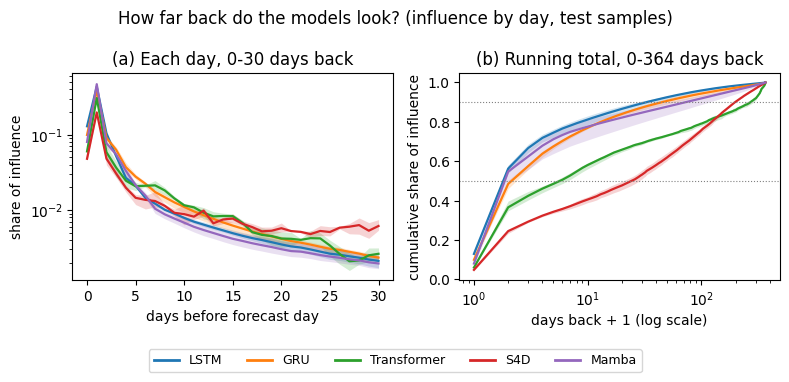

Hình: Mô hình dựa vào những ngày nào khi dự báo? Phương pháp Integrated Gradients (IG) chia con số dự báo thành phần đóng góp của từng ô đầu vào (một biến ở một ngày); 'mức ảnh hưởng' của ô là độ lớn phần đóng góp đó, không kể dấu tăng hay giảm. Hình cộng mức ảnh hưởng theo từng ngày rồi chia cho tổng của 365 ngày (không tính thuộc tính lưu vực), trung bình 10.511 mẫu test; đường là trung bình 3 lần huấn luyện (3 hạt giống), dải mờ là khoảng giữa 3 lần. (a) Phần của từng ngày, từ ngày dự báo (0, chỉ có dự báo ECMWF HRES) lùi về 30 ngày; trục dọc log vì phần này giảm rất nhanh. (b) Phần cộng dồn: chỗ đường cắt vạch chấm 0,5 cho biết một nửa ảnh hưởng nằm trong bao nhiêu ngày gần nhất. Kết quả: ngày dự báo và hôm trước chiếm LSTM 56%, GRU 48%, Transformer 37%, S4D 25%, Mamba 55% tổng ảnh hưởng.


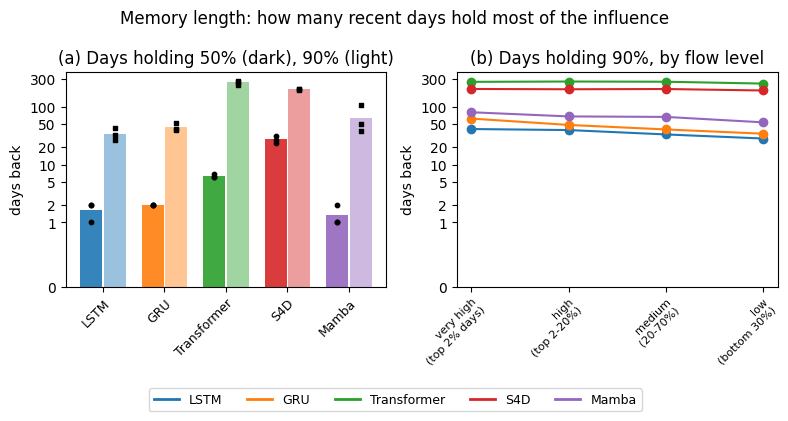

Hình: Mô hình 'nhớ' bao xa? Với mỗi mẫu, đếm cần bao nhiêu ngày gần nhất để gom đủ 50% (cột đậm) hoặc 90% (cột nhạt) tổng mức ảnh hưởng của 364 ngày quá khứ, rồi lấy trung vị qua mẫu; cột là trung bình 3 lần huấn luyện, điểm đen là từng lần (điểm cách xa nhau nghĩa là kết quả đổi nhiều theo hạt giống). (b) Mức 90% tách theo mức lưu lượng của ngày được dự báo, từ ngày lũ (rất cao, 2% số ngày lớn nhất) tới ngày cạn (thấp). Trục dọc giãn đoạn ngắn để đọc được cả 1 ngày lẫn 300 ngày. Kết quả, số ngày giữ 90% ảnh hưởng (trung bình ± độ lệch chuẩn 3 lần): LSTM 34 ± 8, GRU 45 ± 7, Mamba 65 ± 37, S4D 200 ± 1, Transformer 266 ± 23; LSTM nhớ ngắn nhất, Transformer dàn ảnh hưởng ra xa nhất.


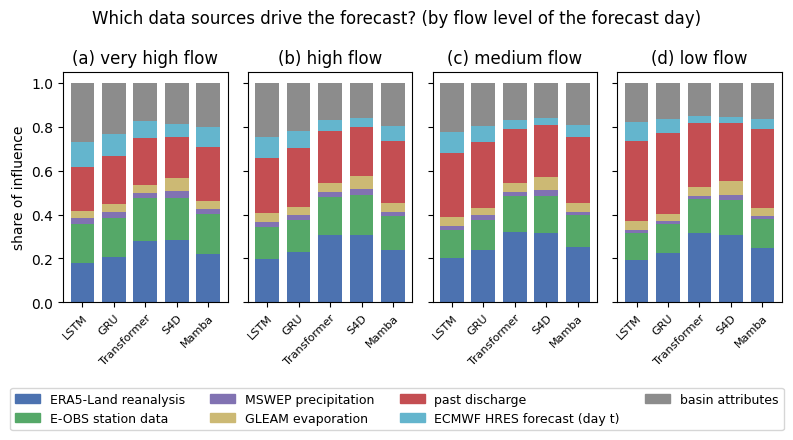

Hình: Mô hình dựa vào nguồn dữ liệu nào? Mỗi cột là tổng mức ảnh hưởng của một mô hình (bằng 1), chia màu theo nguồn: tái phân tích ERA5-Land, lưới trạm E-OBS, mưa MSWEP, bốc hơi GLEAM, lưu lượng quá khứ, dự báo ECMWF HRES ngày t, thuộc tính lưu vực. Bốn ô là bốn mức lưu lượng của ngày được dự báo: rất cao (2% số ngày lớn nhất, ngày lũ), cao, trung bình, thấp (30% số ngày nhỏ nhất, ngày cạn). Kết quả: phần của lưu lượng quá khứ ở ngày lũ LSTM 20%, GRU 22%, Transformer 21%, S4D 19%, Mamba 25%; ở ngày cạn LSTM 36%, GRU 37%, Transformer 29%, S4D 27%, Mamba 36%; ngày cạn mọi mô hình dựa vào lưu lượng đã đo nhiều hơn ngày lũ.


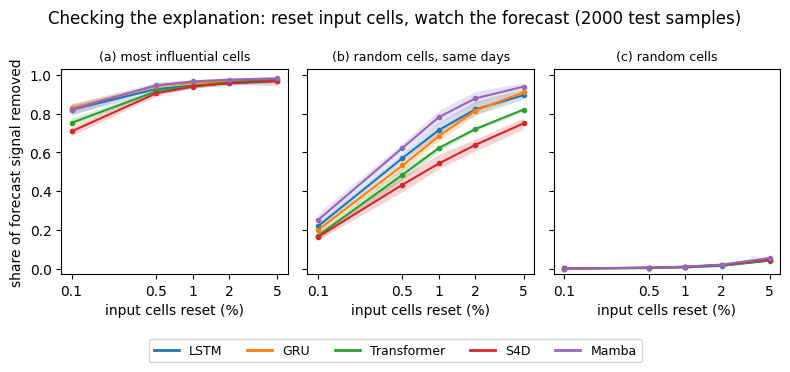

Hình: IG có chỉ đúng những ô mô hình thật sự dùng không? Lấy 2.000 mẫu test, đặt một số ô đầu vào về giá trị trung bình của kỳ huấn luyện (coi như xóa thông tin của ô đó) rồi chạy lại mô hình. 'Tín hiệu dự báo' là khoảng cách giữa dự báo của mẫu và dự báo cho một ngày toàn giá trị trung bình; trục dọc là phần khoảng cách bị mất: 1 là dự báo về hẳn mức trung bình, 0 là không đổi. (a) Xóa các ô IG chấm ảnh hưởng lớn nhất; (b) xóa cùng số ô trong đúng các ngày đó nhưng chọn biến ngẫu nhiên (kiểm IG chọn đúng biến, không chỉ đúng ngày); (c) xóa ô ngẫu nhiên. Kết quả: xóa 12 ô (0,1% số ô) theo IG làm mất LSTM 82%, GRU 83%, Transformer 75%, S4D 71%, Mamba 82% tín hiệu, so với 16%-25% khi chọn biến ngẫu nhiên cùng ngày và dưới 0,1% khi chọn ngẫu nhiên.


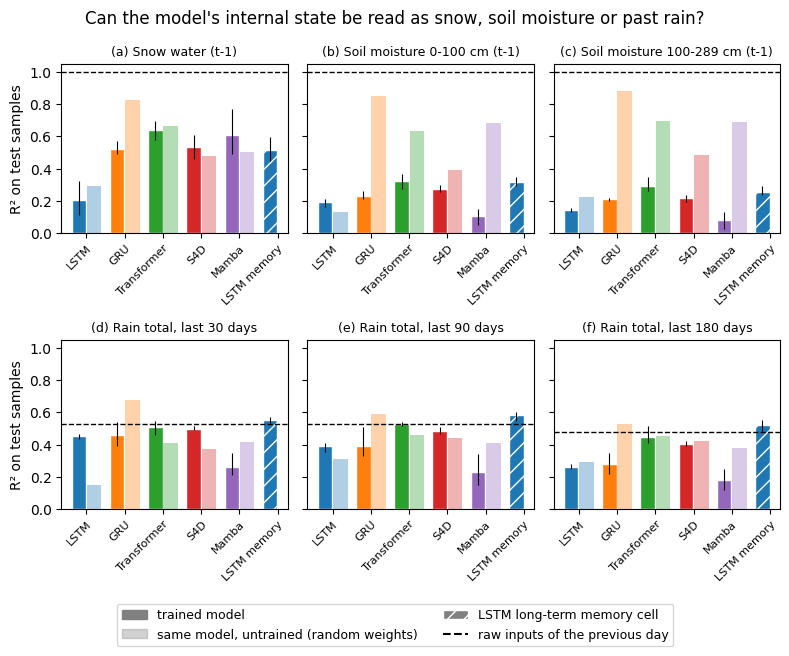

Hình: Bên trong mô hình có 'biết' lượng tuyết, độ ẩm đất hay lượng mưa đã rơi không? Lấy trạng thái bên trong mô hình ở ngày trước ngày dự báo (dãy số mô hình mang theo từ ngày này sang ngày sau) và thử đoán sáu đại lượng từ dãy số đó bằng hồi quy tuyến tính (học trên kỳ huấn luyện, chấm trên kỳ test). R² = 1 là đoán đúng hoàn toàn, 0 là không hơn đoán bằng giá trị trung bình. Cột đậm: mô hình đã huấn luyện (vạch đen là khoảng 3 lần huấn luyện); cột nhạt: cùng mô hình chưa huấn luyện (trọng số ngẫu nhiên); cột gạch chéo: ô nhớ dài hạn của LSTM; đường đứt: đoán thẳng từ dữ liệu đầu vào của ngày trước. Tuyết và ẩm đất vốn là đầu vào nên đường đứt bằng 1. Chỉ khi cột đậm cao hơn cả cột nhạt lẫn đường đứt, và phần cao hơn lớn hơn độ lệch giữa 3 lần huấn luyện, mới nói được mô hình tự học ra đại lượng đó. Kết quả, các trường hợp đạt (R² vượt, trung bình ± độ lệch chuẩn 3 lần): LSTM (ô nhớ dài hạn) ở tổng mưa 30 ngày +0,023 ± 0,022; LSTM (ô nhớ dài hạn) ở tổng mưa 90 ngày +0,056 ± 0,032; LST

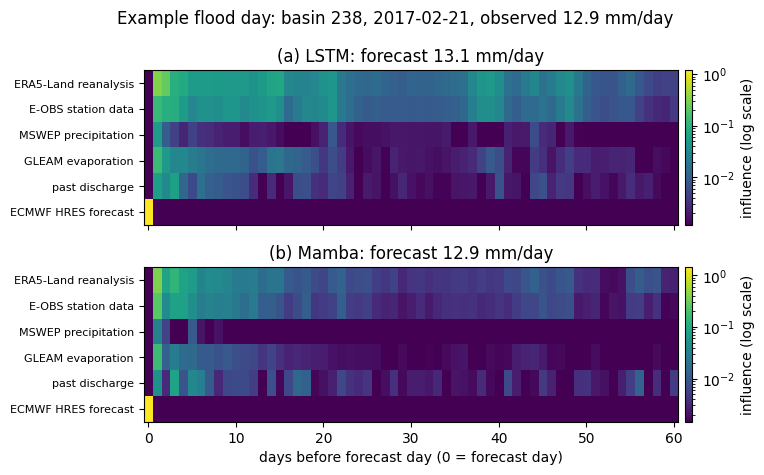

Hình: Giải thích một dự báo lũ cụ thể: lưu vực 238, ngày 2017-02-21, lưu lượng lớn nhất trong ngày đo được 12,9 mm/ngày (lưu lượng quy về độ sâu lớp nước trải đều trên diện tích lưu vực). Ngày này được chọn trong các ngày lũ (mức rất cao) là ngày LSTM và Mamba (hạt giống 111) cùng dự báo gần đúng nhất. Mỗi ô màu là mức ảnh hưởng của một nguồn dữ liệu ở một ngày, từ ngày dự báo (0) lùi về 60 ngày; ô càng sáng càng ảnh hưởng, thang màu log (mỗi bậc màu gấp khoảng 10 lần) để thấy cả các ô nhỏ. Kết quả: LSTM dự báo 13,1 mm/ngày, ô ảnh hưởng nhất là dự báo ECMWF HRES ngày t; Mamba dự báo 12,9 mm/ngày, ô ảnh hưởng nhất là dự báo ECMWF HRES ngày t. Dạng hình này dùng cho trang Giải thích của demo.
=> 6 hình ở /kaggle/working/g_output/Figures. Chạy Phần 9.


core,config,seed,NSE val,margin to 2nd seed,tie
lstm,lstm_L2_x1_lr1e-3,333,0.7681,0.0003,False
gru,gru_L2_x1_lr1e-3,111,0.7707,0.0005,False
transformer,transformer_L2_x1_lr1e-3,222,0.7479,0.0120,False
s4d,s4d_L4_x1_lr1e-3,222,0.7445,0.0063,False
mamba,mamba_L2_x1_lr1e-3,222,0.7672,0.0043,False


file,bytes,sha256
Figures/G_Deletion.png,151768,1f835e0a34eb
Figures/G_Example_Flood.png,147906,c89a12422ecb
Figures/G_Group_Share.png,103477,91abe2ddd477
Figures/G_Lag_Share.png,208520,19569f9bd1c1
Figures/G_Memory_Length.png,128393,d61b46a62da9
Figures/G_Probe.png,162845,d6372c395b80
Tables/G_basin_L90.csv,33635,2072a080cd29
Tables/G_core_diffs.csv,2861,dadabb981ff7
Tables/G_deletion.csv,9548,bd00b27f000e
Tables/G_demo_runs.csv,427,27fb7f553987


mục,giá trị,cần,đạt
15 tệp attribution ig/,15,15,ĐẠT
"Đủ 14 bảng, 6 hình",đủ,đủ,ĐẠT
Run demo không hòa,0,0,ĐẠT
Mảng demo đúng kích thước,"(15, 451, 365), (15, 451, 61, 6)","(15, 451, 365), (15, 451, 61, 6)",ĐẠT
Lưu vực có mẫu: tỉ phần cộng lại = 1,"451 lưu vực, lệch 2.4e-07",<= 1e-4,ĐẠT
Mảng demo hữu hạn ở lưu vực có mẫu,True,True,ĐẠT
Manifest output khớp,38 / 38,tất cả,ĐẠT
Đã xóa thư mục dữ liệu dựng lại,True,True,ĐẠT


Thời gian Phần 9: 9 giây; cả notebook 1.47 giờ
=> Hoàn thành 01_G_C2_XAI. Tải .ipynb, Figures/, Tables/ về repo; ig/ và demo/ giữ ở Output Kaggle cho demo.


In [1]:
# %% Phần 1 - Cài fork (freeze-H2), mamba-ssm, Captum; kiểm môi trường
# Cài fork theo mã commit (Pipeline Mục 9.1), wheel mamba-ssm theo cell Phần 9 của 01_0_MambaSSM_Build (kiểm Python,
# torch, CUDA khớp lúc dựng => phải giữ môi trường cu128), Captum 0.9.0 --no-deps (phụ thuộc matplotlib, numpy,
# packaging, torch>=2.3, tqdm - đều có sẵn; không để pip đổi torch). In bảng thư viện, môi trường, điều kiện; chưa đạt
# => raise để Save & Run All dừng ngay.
import hashlib
import importlib
import importlib.metadata as md
import json
import os
import platform
import shutil
import subprocess
import sys
import time
from pathlib import Path

import pandas as pd
from IPython.display import HTML, display

SESSION_T0 = time.time()
NOTEBOOK = "01_G_C2_XAI"
STEP = "G"
NH_REPO = "https://github.com/Ticasslo/neuralhydrology.git"
NH_COMMIT = "840450f85958538903b16f281ca432d40e0a88e1"   # tag freeze-H2
CAPTUM_VERSION = "0.9.0"                                 # PyPI 17/4/2026, Python >= 3.10, torch >= 2.3
CHECK_LIBS = ["numpy", "pandas", "xarray", "torch", "scipy", "scikit-learn", "matplotlib", "packaging", "tqdm",
              "ruamel.yaml"]
NH_MODULES = ["neuralhydrology.modelzoo.sequential_forecast", "neuralhydrology.modelzoo.sf_cores",
              "neuralhydrology.modelzoo.inputlayer", "neuralhydrology.datasetzoo.lamah",
              "neuralhydrology.datautils.gpu_loader", "neuralhydrology.datautils.utils"]
TORCH_RUNS = "2.11.0+cu128"              # torch của mọi run C2 (ảnh Kaggle 10/2026)

IS_KAGGLE = Path("/kaggle/working").exists()
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("g_work")
OUT_DIR = WORK_DIR / "g_output"
WHEEL_ROOTS = [Path("/kaggle/input"), WORK_DIR / "wheels"]
WORK_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)


def installed_versions(libs):
    # Phiên bản đang cài trên đĩa (không phụ thuộc thứ đã nạp vào bộ nhớ).
    out = {}
    for lib in libs:
        try:
            out[lib] = md.version(lib)
        except md.PackageNotFoundError:
            out[lib] = None
    return out


def mem_gb(key):
    # Đọc /proc/meminfo (kB) => GB.
    for line in Path("/proc/meminfo").read_text().splitlines():
        if line.startswith(key + ":"):
            return int(line.split()[1]) / 1024 ** 2
    return None


def show(title, df, digits=4):
    # Bảng HTML: số thực làm tròn `digits` chữ số, ô trống hiện "-".
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(df.style.hide(axis="index").format(precision=digits, na_rep="-"))


def show_checks(checks, title="Điều kiện"):
    # checks: [(mục, giá trị, cần, đạt)]; trả True nếu mọi dòng đạt.
    show(title, pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": str(c), "đạt": "ĐẠT" if d else "KHÔNG"}
                              for a, b, c, d in checks]))
    return all(c[3] for c in checks)


def run(cmd):
    subprocess.run(cmd, check=True)


def installed_commit(dist):
    # Commit pip ghi lúc cài từ git (direct_url.json của bản cài).
    text = md.distribution(dist).read_text("direct_url.json")
    return json.loads(text)["vcs_info"]["commit_id"] if text else None


def mamba_install():
    # Chép từ 01_0_MambaSSM_Build Phần 9: tìm build_info.json, kiểm Python/torch/CUDA khớp lúc dựng, sha256, cài --no-deps,
    # chạy thử một khối Mamba xuôi + ngược.
    import torch
    infos = [p for root in WHEEL_ROOTS if root.exists() for p in root.rglob("build_info.json")]
    if not infos:
        raise FileNotFoundError("Không thấy build_info.json: gắn Output của notebook 01_0_MambaSSM_Build làm Input")
    if len(infos) > 1:
        print("Thấy nhiều build_info.json, dùng tệp đầu tiên:", *infos, sep="\n  ")
    info_path = infos[0]
    info = json.loads(info_path.read_text())
    now = {"python": platform.python_version(), "torch": torch.__version__, "torch_cuda": torch.version.cuda}
    diff = {k: (info[k], v) for k, v in now.items() if info[k] != v}
    if diff:
        raise RuntimeError(f"Môi trường khác lúc dựng wheel (lúc dựng, bây giờ): {diff}. Copy & Edit một notebook C2 "
                           "đã chạy để giữ môi trường cu128")
    gpu_cc = torch.cuda.get_device_capability(0) if torch.cuda.is_available() else None
    if gpu_cc != (7, 5):
        raise RuntimeError(f"Wheel chỉ có mã cho {info['arch']} (T4), GPU hiện tại: {gpu_cc}")
    wheels = []
    for name, digest in info["wheels"].items():
        whl = info_path.parent / name
        if hashlib.sha256(whl.read_bytes()).hexdigest() != digest:
            raise RuntimeError(f"sha256 của {name} không khớp build_info.json")
        wheels.append(str(whl))
    torch_dist = md.version("torch")
    run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", *wheels])
    if md.version("torch") != torch_dist:
        raise RuntimeError("torch bị đổi sau khi cài wheel, khởi động lại phiên và kiểm lại lệnh cài")
    from mamba_ssm import Mamba
    m = Mamba(d_model=16).cuda()
    y = m(torch.randn(2, 8, 16, device="cuda", requires_grad=True))
    y.sum().backward()
    if not torch.isfinite(y).all():
        raise RuntimeError("Khối Mamba chạy thử ra NaN/inf")
    print(f"mamba-ssm đã cài từ {info_path.parent} (dựng {info['built_at']}, torch {info['torch']}, {info['arch']}); "
          f"chạy thử xuôi + ngược đạt")
    return info, info_path


# Cài fork và Captum (không editable, như các notebook trước); ghi thư viện trước/sau để biết pip có đổi gì không
before = installed_versions(CHECK_LIBS)
run([sys.executable, "-m", "pip", "install", "-q", f"git+{NH_REPO}@{NH_COMMIT}"])
run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", f"captum=={CAPTUM_VERSION}"])
after = installed_versions(CHECK_LIBS)
importlib.invalidate_caches()
changed = [k for k in CHECK_LIBS if before[k] != after[k]]
NH_INSTALLED_COMMIT = installed_commit("neuralhydrology")
MAMBA_BUILD_INFO, MAMBA_INFO_PATH = mamba_install()
extra = installed_versions(["neuralhydrology", "mamba_ssm", "causal_conv1d", "captum"])

show("Thư viện (sau khi cài fork, mamba-ssm, Captum)", pd.DataFrame({
    "Thư viện": list(extra) + CHECK_LIBS,
    "Phiên bản": [f"{extra['neuralhydrology']} (commit {(NH_INSTALLED_COMMIT or 'không rõ')[:7]})"]
                 + [extra[k] or "THIẾU" for k in list(extra)[1:]] + [after[k] or "THIẾU" for k in CHECK_LIBS],
    "pip đổi?": [""] * len(extra) + [f"từ {before[k]}" if before[k] != after[k] else "" for k in CHECK_LIBS]}))

import torch

n_gpu = torch.cuda.device_count()
gpus = [f"{i}: {torch.cuda.get_device_name(i)} (cc {'.'.join(map(str, torch.cuda.get_device_capability(i)))}, "
        f"{torch.cuda.get_device_properties(i).total_memory / 1024 ** 3:.1f} GB)" for i in range(n_gpu)]
ENV = {
    "Python": platform.python_version(),
    "torch / CUDA của torch": f"{torch.__version__} / {torch.version.cuda}",
    "cuDNN": torch.backends.cudnn.version(),
    "GPU": "; ".join(gpus) or "không có GPU",
    "Số CPU": os.cpu_count(),
    "RAM tổng / còn trống (GB)": f"{mem_gb('MemTotal'):.1f} / {mem_gb('MemAvailable'):.1f}",
    "Đĩa trống ở WORK_DIR (GB)": f"{shutil.disk_usage(WORK_DIR).free / 1024 ** 3:.1f}",
    "Ngày dựng ảnh Kaggle": Path("/etc/build_date").read_text().strip() if Path("/etc/build_date").exists() else "không có",
    "Wheel mamba-ssm": str(MAMBA_INFO_PATH.parent),
}
show("Môi trường", pd.DataFrame({"Mục": list(ENV), "Giá trị": [str(v) for v in ENV.values()]}))

# Nạp thử các module sẽ dùng; sf_cores phải thấy mamba_ssm thì lõi mamba mới dựng được
import_ok = {}
for mod in NH_MODULES + ["captum.attr", "sklearn.linear_model"]:
    try:
        importlib.import_module(mod)
        import_ok[mod] = "ĐẠT"
    except Exception as e:
        import_ok[mod] = f"LỖI: {type(e).__name__}: {e}"
for mod, v in import_ok.items():
    if v != "ĐẠT":
        print(f"{mod}: {v}")

from neuralhydrology.modelzoo import sf_cores

nh_path = Path(importlib.import_module("neuralhydrology").__file__).resolve()
ok = show_checks([
    ("Cài đúng commit freeze-H2", (NH_INSTALLED_COMMIT or "?")[:7], NH_COMMIT[:7], NH_INSTALLED_COMMIT == NH_COMMIT),
    ("Nạp neuralhydrology từ site-packages", nh_path.parent, "site-packages",
     "site-packages" in str(nh_path) or "dist-packages" in str(nh_path)),
    ("Captum", extra["captum"], CAPTUM_VERSION, extra["captum"] == CAPTUM_VERSION),
    ("torch giữ bản của các run C2", torch.__version__, TORCH_RUNS, torch.__version__ == TORCH_RUNS),
    ("pip không đổi thư viện có sẵn", ", ".join(f"{k} {before[k]} => {after[k]}" for k in changed) or "không đổi",
     "không đổi", not changed),
    ("Có GPU T4 (dùng GPU 0)", gpus[0] if gpus else "không có", "T4", n_gpu >= 1 and "T4" in gpus[0]),
    ("Nạp được các module", f"{sum(v == 'ĐẠT' for v in import_ok.values())} / {len(import_ok)}", "tất cả",
     all(v == "ĐẠT" for v in import_ok.values())),
    ("sf_cores thấy mamba_ssm", sf_cores.MambaSSM is not None, True, sf_cores.MambaSSM is not None),
])
if not ok:
    raise RuntimeError("Phần 1 CHƯA đạt (dòng KHÔNG ở bảng Điều kiện) - dừng notebook")
print(f"=> Đạt ({time.time() - SESSION_T0:.0f} giây). Chạy Phần 2.")


# %% Phần 2 - Tìm Output 15 run C2, C2 Compare, A3; kiểm sha256 theo bàn giao; dựng thư mục dữ liệu qmean_mmd, qmax_mmd
# Notebook huấn luyện C2 (khuôn Tools/C_Notebook_Template.py Phần 8) ghi c_output/environment.json (run_dir tính từ
# /kaggle/working của notebook đó), summary.json, manifest.csv (cột "tệp"); 13_C2_LamaHCEExt_Compare ghi
# c2_compare/Tables/C2_handoff.csv (sha256 best_model.pt, config.yml, train_data_scaler.yml, NPZ test hạn 1),
# environment.json (sha256 hai tệp A3 đã dùng), manifest.csv (cột "file"). Nhận run theo environment.json, không theo tên
# thư mục Input. Thư mục dữ liệu: chép Phần 3.1 của khuôn H (đã chạy đạt ở 24 run H, trùng B3 Phần 3), cùng đường dẫn
# /kaggle/working/LamaH_q_mmd_input như lúc huấn luyện; kiểm trên đúng khoảng ngày của config C2.
import random
import re

import numpy as np
import yaml

from neuralhydrology.datasetzoo.lamah import (_normalize_discharge, load_lamah_attributes, load_lamah_discharge,
                                              load_lamah_forcing)

INPUT_ROOT = Path(os.environ.get("G_INPUT_ROOT", "/kaggle/input" if IS_KAGGLE else "g_input"))
CONFS = ["lstm_L2_x1_lr1e-3", "gru_L2_x1_lr1e-3", "transformer_L2_x1_lr1e-3", "s4d_L4_x1_lr1e-3",
         "mamba_L2_x1_lr1e-3"]           # C2 mức cùng tham số của 5 lõi (13_C2_LamaHCEExt_Compare V1)
CORES = [c.split("_")[0] for c in CONFS]
SEEDS = [111, 222, 333]
N_BASINS = 451
C2_COMPARE_VERSION, A3_VERSION = 1, 1
C2_COMMIT = "db6dc1ffcd8c14994cd80be3ed8ff417002c01a1"   # tag freeze-C, nơi các run C2 huấn luyện
RUN_RE = re.compile(r"^C2_(lstm|gru|transformer|s4d|mamba)_L(\d)_x1_lr1e-3_seed(\d+)$")
Q_DIR = WORK_DIR / "LamaH_q_mmd_input"
SUB_A = "A_basins_total_upstrm"
TS_DAILY = Path("2_timeseries") / "daily"
DATE_COLS = ["YYYY", "MM", "DD"]
Q_SRC = {"qmean_mmd": "qmean", "qmax_mmd": "qmax"}  # cột mới => cột của D_gauges
Q_NEW = list(Q_SRC)
LABEL_TOL = 1e-12
random.seed(0)


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as fp:
        for chunk in iter(lambda: fp.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def inside(root, relative):
    # Đường dẫn trong manifest/environment phải nằm trong thư mục nguồn.
    root = Path(root).resolve()
    path = (root / relative).resolve()
    if Path(relative).is_absolute() or not path.is_relative_to(root):
        raise ValueError(f"Đường dẫn nằm ngoài nguồn Input: {relative}")
    return path


def check_manifest(root, manifest_path, required=()):
    # Mọi tệp trong manifest khớp sha256; mọi tệp `required` có trong manifest. Trả (số tệp, danh sách lệch).
    man = pd.read_csv(manifest_path)
    col = "file" if "file" in man else "tệp"
    if col not in man or "sha256" not in man or man[col].duplicated().any():
        raise ValueError(f"Manifest sai cột hoặc trùng đường dẫn: {manifest_path}")
    known = set(man[col])
    rel = [Path(p).resolve().relative_to(Path(root).resolve()).as_posix() for p in required]
    bad = [p for p in rel if p not in known]
    bad += [r for r, dg in zip(man[col], man["sha256"]) if not inside(root, r).is_file() or sha256(inside(root, r)) != dg]
    return len(man), bad


def unique_file(name):
    hits = sorted(INPUT_ROOT.rglob(name))
    if len(hits) != 1:
        raise FileNotFoundError(f"Cần đúng một {name} trong Input, thấy {len(hits)}: {hits}")
    return hits[0]


def find_dir(root, name):
    hits = sorted(p for p in root.rglob(name) if p.is_dir())
    if len(hits) != 1:
        raise FileNotFoundError(f"Cần đúng 1 thư mục '{name}' dưới {root}, thấy {len(hits)}: {hits} - kiểm Input lamah-ce-ext")
    return hits[0]


def find_key(obj, key):
    # Tìm khóa `key` ở mọi tầng của dict lồng nhau (environment.json).
    if isinstance(obj, dict):
        if key in obj:
            return obj[key]
        for v in obj.values():
            hit = find_key(v, key)
            if hit is not None:
                return hit
    return None


# (1) C2 Compare: manifest, bàn giao 15 run, A3 đã dùng
C2C_DIR = unique_file("c2_summary.json").parent
c2c_files, c2c_bad = check_manifest(C2C_DIR, C2C_DIR / "manifest.csv",
                                    [C2C_DIR / "Tables" / "C2_handoff.csv", C2C_DIR / "environment.json"])
HANDOFF = pd.read_csv(C2C_DIR / "Tables" / "C2_handoff.csv")
HANDOFF = HANDOFF[HANDOFF["cấu hình"].isin(CONFS)].reset_index(drop=True)
C2C_ENV = json.loads((C2C_DIR / "environment.json").read_text(encoding="utf-8"))
a3_used = find_key(C2C_ENV, "A3") or {}
A3_PATHS = {n: unique_file(n) for n in ["A3_persistence_predictions.npz", "A3_Q_source_window.npz"]}
a3_bad = [n for n, p in A3_PATHS.items() if a3_used.get("files", {}).get(n) != sha256(p)]

# (2) Output 15 notebook C2: nhận theo environment.json, kiểm với bàn giao
found = {}
for env_path in sorted(INPUT_ROOT.rglob("c_output/environment.json")):
    env = json.loads(env_path.read_text(encoding="utf-8"))
    m = RUN_RE.match(env.get("experiment_name", ""))
    conf = f"{m.group(1)}_L{m.group(2)}_x1_lr1e-3" if m else None
    if conf not in CONFS:
        continue
    key = (conf, int(m.group(3)))
    if key in found:
        raise RuntimeError(f"Gắn trùng Output của run {key}")
    root = env_path.parent.parent                # thư mục ứng với /kaggle/working của notebook đó
    found[key] = {"root": root, "out": env_path.parent, "run": inside(root, env["run_dir"]), "env": env}

rows, RUNS = [], {}
for _, h in HANDOFF.iterrows():
    key = (h["cấu hình"], int(h["hạt giống"]))
    row = {"cấu hình": key[0], "hạt giống": key[1], "notebook": h["notebook"], "epoch chọn": int(h["epoch chọn"]),
           "NSE val": float(h["NSE val"])}
    if key not in found:
        rows.append({**row, "lỗi": "THIẾU Input"})
        continue
    r = found[key]
    run_dir, env = r["run"], r["env"]
    summary = json.loads((r["out"] / "summary.json").read_text(encoding="utf-8"))
    cfg = yaml.safe_load((run_dir / "config.yml").read_text(encoding="utf-8-sig"))
    n_files, bad = check_manifest(r["root"], r["out"] / "manifest.csv",
                                  [run_dir / "config.yml", run_dir / "best_model.pt",
                                   run_dir / "train_data" / "train_data_scaler.yml"])
    core, depth = key[0].split("_")[0], int(key[0].split("_")[1][1:])
    errs = [msg for ok_, msg in [
        (env.get("notebook") == h["notebook"], "tên notebook"),
        (run_dir.name == Path(h["thư mục run"]).name, "thư mục run"),
        (env.get("neuralhydrology_commit") == C2_COMMIT, "commit"),
        (summary.get("status") == "xong" and summary.get("saved_epoch") == int(h["epoch chọn"]), "trạng thái/epoch chọn"),
        (sha256(run_dir / "best_model.pt") == h["sha256 best_model.pt"], "sha256 best_model.pt"),
        (sha256(run_dir / "config.yml") == h["sha256 config.yml"], "sha256 config.yml"),
        (sha256(run_dir / "train_data" / "train_data_scaler.yml") == h["sha256 train_data_scaler.yml"], "sha256 scaler"),
        (not bad, "manifest"),
        (cfg.get("model") == "sequential_forecast" and cfg.get("sf_core") == core and int(cfg.get("sf_layers")) == depth
         and int(cfg.get("seed")) == key[1] and int(cfg.get("seq_length")) == 365
         and int(cfg.get("forecast_seq_length")) == 1 and cfg.get("target_variables") == ["qmax"], "config"),
        (Path(cfg.get("data_dir", "")) == Q_DIR, "data_dir của config khác thư mục dựng lại"),
        ((C2C_DIR / h["NPZ"]).is_file(), "NPZ C2"),
    ] if not ok_]
    RUNS[key] = {**r, "cfg": cfg, "summary": summary, "npz": C2C_DIR / h["NPZ"], "n_params": summary.get("n_params")}
    rows.append({**row, "thư mục run": run_dir.name, "số tham số": summary.get("n_params"), "tệp manifest": n_files,
                 "lỗi": "; ".join(errs) or "-"})
RUN_TABLE = pd.DataFrame(rows)
show(f"Output {len(RUNS)} / {len(CONFS) * len(SEEDS)} run C2", RUN_TABLE)
extra_runs = sorted(set(found) - set(RUNS))

# (3) Dữ liệu: danh sách lưu vực, thư mục Q mm/ngày (chép Phần 3.1 khuôn H)
LAMAH_DIR = find_dir(INPUT_ROOT, "LamaH_extended")
EXP_DIR = find_dir(INPUT_ROOT, "Experiments")
basins = (EXP_DIR / "basins_filtered.txt").read_text().split()
AREA = load_lamah_attributes(LAMAH_DIR, sub_dataset="lamah_a")["area_gov"]


def read_text_csv(path, usecols=None):
    # Đọc CSV ';' dạng chữ (không đổi sang số), ô trống giữ là chuỗi rỗng; thêm khóa ngày dạng số để ghép.
    df = pd.read_csv(path, sep=";", dtype=str, keep_default_na=False, usecols=usecols)
    df["_key"] = pd.to_datetime(df[DATE_COLS].astype(int).rename(columns={"YYYY": "year", "MM": "month", "DD": "day"}))
    return df


def q_raw(data_dir, basin, src):
    # Q (m³/s) của D_gauges, -999 => NaN, đúng hàm bộ nạp gọi cho nhãn.
    return load_lamah_discharge(data_dir, basin, temporal_resolution="1D", normalize_discharge=False, target_name=src)[src]


def q_mmd(data_dir, basin, src):
    # Q (m³/s) => mm/ngày theo area_gov, đúng phép tính bộ nạp dùng cho nhãn.
    return _normalize_discharge(ser=q_raw(data_dir, basin, src), area=AREA.loc[basin], temporal_resolution="1D")


def fmt(ser):
    # float64 => chữ 17 chữ số có nghĩa, NaN => ô trống
    return ser.map(lambda v: "" if pd.isna(v) else format(v, ".17g"))


def build_basin_file(basin):
    # Ghép 2 cột Q mm/ngày vào tệp khí tượng theo ngày; ghi qua tệp tạm rồi đổi tên để không để lại tệp dở.
    forcing = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv")
    for new, src in Q_SRC.items():
        forcing[new] = fmt(forcing["_key"].map(q_mmd(LAMAH_DIR, basin, src)))
    dst = Q_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv"
    tmp = dst.with_suffix(".tmp")
    forcing.drop(columns="_key").to_csv(tmp, sep=";", index=False)
    tmp.rename(dst)


def has_new_cols(path):
    return path.exists() and all(c in path.open().readline().strip().split(";") for c in Q_NEW)


def rel_diff(a, b):
    # Lệch tương đối lớn nhất trên các ô cả hai có số, và số ô khác trạng thái trống.
    both = ~np.isnan(a) & ~np.isnan(b)
    rel = np.abs(a[both] - b[both]) / np.maximum(np.abs(b[both]), 1e-300)
    return (float(rel.max()) if rel.size else 0.0), int((np.isnan(a) != np.isnan(b)).sum())


t0 = time.time()
(Q_DIR / SUB_A / TS_DAILY).mkdir(parents=True, exist_ok=True)
for link, target in [(Q_DIR / SUB_A / "1_attributes", LAMAH_DIR / SUB_A / "1_attributes"),
                     (Q_DIR / "D_gauges", LAMAH_DIR / "D_gauges")]:
    if not (link.exists() or link.is_symlink()):
        link.symlink_to(target, target_is_directory=True)
todo = [b for b in basins if not has_new_cols(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")]
for b in todo:
    build_basin_file(b)
n_ok = sum(has_new_cols(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv") for b in basins)

# Kiểm 3 lưu vực ngẫu nhiên giữ nguyên cột cũ; cả 451 lưu vực đọc lại bằng đường bộ nạp, trên khoảng ngày của config
# C2 (364 ngày khởi động trước kỳ train tới hết kỳ test)
keep_rows = []
for b in random.sample(basins, 3):
    src = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    new = read_text_csv(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    keep_rows.append(new.drop(columns=Q_NEW).equals(src))
if not RUNS:
    raise RuntimeError("Chưa nhận được run C2 nào - kiểm Input (bảng ở trên)")
CFG0 = next(iter(RUNS.values()))["cfg"]
WIN_START = pd.to_datetime(CFG0["train_start_date"], dayfirst=True) - pd.Timedelta(days=364)
WIN_END = pd.to_datetime(CFG0["test_end_date"], dayfirst=True)
max_label = max_mean = 0.0
n_nan = 0
for b in basins:
    df = load_lamah_forcing(Q_DIR, b, sub_dataset="lamah_a").loc[WIN_START:WIN_END]
    for col, src in Q_SRC.items():
        r_, n_ = rel_diff(df[col].to_numpy(), q_mmd(Q_DIR, b, src).reindex(df.index).to_numpy())
        n_nan += n_
        if col == "qmax_mmd":
            max_label = max(max_label, r_)
        else:
            max_mean = max(max_mean, r_)

periods = {(c["cfg"]["train_start_date"], c["cfg"]["test_start_date"], c["cfg"]["test_end_date"]) for c in RUNS.values()}
ok = show_checks([
    ("C2 Compare: manifest", f"{c2c_files - len(c2c_bad)} / {c2c_files} tệp khớp", "tất cả", not c2c_bad),
    ("Bàn giao có 15 run x1", len(HANDOFF), 15, len(HANDOFF) == 15),
    ("A3: sha256 trùng bản C2 Compare đã dùng", ", ".join(a3_bad) or "trùng", "trùng", not a3_bad),
    ("Run C2 có đủ và không lỗi", f"{int(RUN_TABLE['lỗi'].eq('-').sum())} / 15", 15,
     len(RUNS) == 15 and bool(RUN_TABLE["lỗi"].eq("-").all())),
    ("Không gắn Output C2 ngoài 15 run", extra_runs or "không", "không", not extra_runs),
    ("15 config cùng kỳ dữ liệu", len(periods), 1, len(periods) == 1),
    ("Danh sách lưu vực", f"{len(basins)} ({len(set(basins))} mã khác nhau)", N_BASINS,
     len(basins) == len(set(basins)) == N_BASINS),
    ("Tệp khí tượng có qmean_mmd, qmax_mmd", f"{n_ok} / {len(basins)} (dựng mới {len(todo)})", len(basins),
     n_ok == len(basins)),
    ("3 lưu vực ngẫu nhiên giữ nguyên cột cũ", f"{sum(keep_rows)} / 3", 3, all(keep_rows)),
    (f"qmax_mmd = nhãn qmax, qmean_mmd = qmean D_gauges ({WIN_START.date()} - {WIN_END.date()})",
     f"lệch {max_label:.2g} / {max_mean:.2g}; ô trống khác {n_nan}", f"<= {LABEL_TOL}; 0",
     max(max_label, max_mean) <= LABEL_TOL and n_nan == 0),
], "Điều kiện Phần 2")
print(f"Thời gian Phần 2: {time.time() - t0:.0f} giây")
if not ok:
    raise RuntimeError("Phần 2 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 3.")


# %% Phần 3 - Nạp 15 mô hình, rút mẫu phân tầng theo mức lưu lượng, kiểm dự báo trùng NPZ C2 và đường tính đạo hàm
# Dữ liệu: một dataset kỳ test cho cả 451 lưu vực (basin=None, scaler đã lưu => không lọc mẫu, như Tester), dùng chung
# cho 15 run vì 15 config có cùng biến đầu vào và scaler trùng sha256. Mẫu: mỗi lưu vực 6 ngày đích mỗi mức của qmax
# quan trắc (ngưỡng riêng lưu vực trên qmax 1981-2013, Pipeline Mục 6.2: rất cao xác suất vượt 0-0.02, cao 0.02-0.2,
# trung bình 0.2-0.7, thấp 0.7-1), chỉ ngày có quan trắc và dự báo hữu hạn ở cả 15 run; mức thiếu ngày thì lấy hết.
# Đầu vào gói thành 3 tensor (pha quá khứ [mẫu, ngày, cột], ngày t [mẫu, 1, cột], thuộc tính [mẫu, cột]) + mặt nạ NaN:
# Captum nhân (đầu vào - gốc) với đạo hàm nên ô NaN truyền dưới dạng 0, hàm bọc đặt lại NaN trước khi gọi mô hình
# (InputLayer bỏ nhóm có ô NaN khỏi masked mean, inputlayer.py dòng 310-330 ở 840450f). Chế độ tính đạo hàm: eval, riêng
# nn.LSTM/nn.GRU của lõi RNN ở train() để cuDNN cho backward (RNNCore không có dropout trong, sf_cores.py dòng 84-85).
# Kiểm: (1) dự báo eval trùng NPZ C2 (dung sai DemoRuntime 2e-5 mm/ngày + 1e-6 tương đối); (2) hàm bọc + chế độ đạo
# hàm trùng dự báo eval; (3) đạo hàm hữu hạn và ô NaN có đạo hàm 0.
from neuralhydrology.datasetzoo import get_dataset
from neuralhydrology.datautils.utils import load_scaler
from neuralhydrology.modelzoo import get_model
from neuralhydrology.utils.config import Config

DEVICE = torch.device("cuda:0")
TABLE_DIR = OUT_DIR / "Tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
LEVELS = ["very high", "high", "medium", "low"]  # xác suất vượt 0-0.02, 0.02-0.2, 0.2-0.7, 0.7-1
LEVEL_EXCEED = [0.02, 0.2, 0.7]
N_PER_LEVEL = 6
SAMPLE_SEED = 2026
REF_YEARS = ("1981-01-01", "2013-12-31")           # qmax trước kỳ test, như A1 và bộ đánh giá
PRED_ATOL, PRED_RTOL = 2e-5, 1e-6                  # Workspace/07_Demo/DemoRuntime/forecast.py
BATCH = 512
SEASONS = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM", 6: "JJA", 7: "JJA", 8: "JJA",
           9: "SON", 10: "SON", 11: "SON"}


def group_label(cols):
    # Tên nhóm nguồn từ tiền tố cột (ERA5L_, EOBS_, ...); hai cột Q quan trắc => "Q".
    if all(c.startswith("q") for c in cols):
        return "Q"
    prefixes = {c.split("_")[0] for c in cols}
    if len(prefixes) != 1:
        raise ValueError(f"Nhóm trộn nhiều nguồn: {cols}")
    return prefixes.pop()


def run_cfg(r):
    # Config của run, đổi đường dẫn danh sách lưu vực sang Input và thiết bị sang GPU 0.
    cfg = Config(r["run"] / "config.yml")
    basin_file = EXP_DIR / "basins_filtered.txt"
    cfg.update_config({"train_basin_file": basin_file, "validation_basin_file": basin_file,
                       "test_basin_file": basin_file, "device": "cuda:0", "data_dir": Q_DIR})
    return cfg


def ig_mode(model):
    # Chế độ tính đạo hàm: mọi dropout ở eval; nn.LSTM/nn.GRU ở train() để cuDNN có backward (không có dropout trong).
    model.eval()
    rnn = getattr(model.core, "rnn", None)
    if rnn is not None:
        if rnn.dropout != 0:
            raise RuntimeError("RNN có dropout trong - không dùng train() thay eval được")
        rnn.train()
    return model


def forward_packed(model, h, f, s, mh, mf):
    # Hàm bọc cho Captum: dựng lại dict đầu vào của mô hình, ô có mặt nạ đặt lại NaN; trả dự báo chuẩn hóa ngày t.
    nan = torch.tensor(float("nan"), device=h.device, dtype=h.dtype)
    h = torch.where(mh, nan, h)
    f = torch.where(mf, nan, f)
    data = {"x_d_hindcast": {k: h[..., i:i + 1] for i, k in enumerate(HIND_FEATS)},
            "x_d_forecast": {k: f[..., i:i + 1] for i, k in enumerate(FORE_FEATS)},
            "x_s": s}
    return model(data)["y_hat"][:, -1, 0]


def chunks(n, size=BATCH):
    return [slice(i, min(i + size, n)) for i in range(0, n, size)]


def to_dev(*xs):
    return [x.to(DEVICE) for x in xs]


t0 = time.time()
# (1) Config, scaler, biến đầu vào chung của 15 run
CFGS = {k: run_cfg(r) for k, r in RUNS.items()}
cfg_ref = CFGS[(CONFS[0], SEEDS[0])]
same_inputs = all((c.hindcast_inputs, c.forecast_inputs, c.static_attributes, c.seq_length, c.forecast_seq_length,
                   c.nan_handling_method, c.timestep_counter, c.forecast_input_mode)
                  == (cfg_ref.hindcast_inputs, cfg_ref.forecast_inputs, cfg_ref.static_attributes, cfg_ref.seq_length,
                      cfg_ref.forecast_seq_length, cfg_ref.nan_handling_method, cfg_ref.timestep_counter,
                      cfg_ref.forecast_input_mode) for c in CFGS.values())
same_scaler = HANDOFF["sha256 train_data_scaler.yml"].nunique() == 1
HIND_FEATS = list(cfg_ref.hindcast_inputs_flattened)
FORE_FEATS = list(cfg_ref.forecast_inputs_flattened)
STATICS = list(cfg_ref.static_attributes)
HIND_GROUPS = [list(g) if isinstance(g, (list, tuple)) else g for g in cfg_ref.hindcast_inputs]
FORE_GROUPS = [list(g) if isinstance(g, (list, tuple)) else g for g in cfg_ref.forecast_inputs]
if not all(isinstance(g, list) for g in HIND_GROUPS + FORE_GROUPS):
    raise RuntimeError("Config không chia nhóm nguồn (masked mean) - khác giao thức C2")
GROUP_OF = {c: group_label(g) for g in HIND_GROUPS + FORE_GROUPS for c in g}   # cột => nhóm nguồn
SCALER = load_scaler(next(iter(RUNS.values()))["run"])
Q_SCALE = float(SCALER["xarray_feature_scale"]["qmax"].item())
Q_CENTER = float(SCALER["xarray_feature_center"]["qmax"].item())
show("Biến đầu vào chung của 15 run", pd.DataFrame(
    [{"pha": "quá khứ", "nhóm": group_label(g), "số cột": len(g), "cột": ", ".join(g)} for g in HIND_GROUPS]
    + [{"pha": "ngày t", "nhóm": group_label(g), "số cột": len(g), "cột": ", ".join(g)} for g in FORE_GROUPS]
    + [{"pha": "tĩnh", "nhóm": "static", "số cột": len(STATICS), "cột": ", ".join(STATICS[:6]) + ", ..."}]))

# (2) Dataset kỳ test 451 lưu vực, chỉ mục (lưu vực, ngày đích) => mẫu
DATASET = get_dataset(cfg_ref, is_train=False, period="test", basin=None, scaler=SCALER)
INDEX = {}
for i, (b, idx) in DATASET.lookup_table.items():
    INDEX[(str(b), pd.Timestamp(DATASET._dates[b]["1D"][idx[0]]))] = i
print(f"Dataset test: {len(DATASET):,} mẫu, {len(DATASET.basins)} lưu vực ({time.time() - t0:.0f} giây)")

# (3) Mức lưu lượng ngày đích, ngày hợp lệ ở cả 15 run, rút mẫu phân tầng
NPZ = {}
for key, r in RUNS.items():
    with np.load(r["npz"], allow_pickle=False) as d:
        NPZ[key] = {k: d[k] for k in ["dates", "basin_ids", "obs_mm_day", "sim_raw_mm_day"]}
ref_npz = NPZ[(CONFS[0], SEEDS[0])]
NPZ_DATES = pd.DatetimeIndex(ref_npz["dates"])
NPZ_IDS = [str(b) for b in ref_npz["basin_ids"]]
same_ctx = all(np.array_equal(v["dates"], ref_npz["dates"]) and list(map(str, v["basin_ids"])) == NPZ_IDS
               and np.array_equal(v["obs_mm_day"], ref_npz["obs_mm_day"], equal_nan=True) for v in NPZ.values())
OBS = ref_npz["obs_mm_day"]
valid = np.isfinite(OBS) & np.all([np.isfinite(v["sim_raw_mm_day"]) for v in NPZ.values()], axis=0)
rng = np.random.default_rng(SAMPLE_SEED)
sample_rows, level_rows = [], []
for j, b in enumerate(NPZ_IDS):
    ref = q_mmd(LAMAH_DIR, b, "qmax").loc[REF_YEARS[0]:REF_YEARS[1]].dropna().to_numpy()
    if ref.size == 0:
        level_rows.append({"lưu vực": b, "số năm tham chiếu": 0})
        continue
    thr = np.quantile(ref, [1 - p for p in LEVEL_EXCEED])           # ngưỡng rất cao > cao > trung bình
    obs_b = OBS[:, j]
    lvl = np.where(obs_b >= thr[0], 0, np.where(obs_b >= thr[1], 1, np.where(obs_b >= thr[2], 2, 3)))
    for li, name in enumerate(LEVELS):
        days = np.flatnonzero(valid[:, j] & (lvl == li))
        pick = np.sort(rng.choice(days, size=min(N_PER_LEVEL, days.size), replace=False)) if days.size else []
        for t in pick:
            sample_rows.append({"basin": b, "date": NPZ_DATES[t], "level": name, "t_index": int(t), "b_index": j,
                                "obs_mm_day": float(obs_b[t])})
    level_rows.append({"lưu vực": b, "số năm tham chiếu": round(ref.size / 365.25, 1),
                       **{f"ngày test mức {n}": int((valid[:, j] & (lvl == li)).sum()) for li, n in enumerate(LEVELS)}})
SAMPLES = pd.DataFrame(sample_rows)
SAMPLES["season"] = SAMPLES["date"].dt.month.map(SEASONS)
SAMPLES["ds_index"] = [INDEX.get((b, d), -1) for b, d in zip(SAMPLES["basin"], SAMPLES["date"])]
LEVEL_TABLE = pd.DataFrame(level_rows)
show("Số mẫu theo mức lưu lượng và mùa", SAMPLES.pivot_table(index="level", columns="season", values="basin",
                                                             aggfunc="size", fill_value=0).reindex(LEVELS).reset_index())

# (4) Gói đầu vào của các mẫu (CPU), kiểm khóa ngoài danh sách biến
H_list, F_list, S_list, extra_keys = [], [], [], set()
for sl in chunks(len(SAMPLES)):
    batch = DATASET.collate_fn([DATASET[int(i)] for i in SAMPLES["ds_index"].iloc[sl]])
    extra_keys |= (set(batch["x_d_hindcast"]) - set(HIND_FEATS)) | (set(batch["x_d_forecast"]) - set(FORE_FEATS))
    H_list.append(torch.cat([batch["x_d_hindcast"][k] for k in HIND_FEATS], dim=-1))
    F_list.append(torch.cat([batch["x_d_forecast"][k] for k in FORE_FEATS], dim=-1))
    S_list.append(batch["x_s"])
H_RAW, F_RAW, S_RAW = torch.cat(H_list), torch.cat(F_list), torch.cat(S_list)
MH, MF = torch.isnan(H_RAW), torch.isnan(F_RAW)
H_IN, F_IN = torch.nan_to_num(H_RAW, nan=0.0), torch.nan_to_num(F_RAW, nan=0.0)
print(f"Gói đầu vào: quá khứ {tuple(H_IN.shape)}, ngày t {tuple(F_IN.shape)}, tĩnh {tuple(S_RAW.shape)}; "
      f"ô NaN quá khứ {MH.float().mean():.2%}, ngày t {MF.float().mean():.2%} ({time.time() - t0:.0f} giây)")

# (5) Nạp 15 mô hình; dự báo eval so NPZ; hàm bọc + chế độ đạo hàm so eval; đạo hàm hữu hạn, ô NaN đạo hàm 0
MODELS, PRED, check_rows = {}, {}, []
for key, r in RUNS.items():
    model = get_model(CFGS[key]).to(DEVICE)
    model.load_state_dict(torch.load(r["run"] / "best_model.pt", map_location=DEVICE, weights_only=True), strict=True)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    model.eval()
    preds = []
    with torch.inference_mode():
        for sl in chunks(len(SAMPLES)):
            h, f, s, mh, mf = to_dev(H_IN[sl], F_IN[sl], S_RAW[sl], MH[sl], MF[sl])
            preds.append(forward_packed(model, h, f, s, mh, mf).float().cpu())
    pred_norm = torch.cat(preds).numpy()
    pred_mm = pred_norm * Q_SCALE + Q_CENTER
    ref_mm = NPZ[key]["sim_raw_mm_day"][SAMPLES["t_index"], SAMPLES["b_index"]]
    npz_ok = bool(np.allclose(pred_mm, ref_mm, atol=PRED_ATOL, rtol=PRED_RTOL))
    # Đường tính đạo hàm trên 256 mẫu đầu
    ig_mode(model)
    sl = slice(0, 256)
    h, f, s, mh, mf = to_dev(H_IN[sl], F_IN[sl], S_RAW[sl], MH[sl], MF[sl])
    h, f, s = (x.clone().requires_grad_(True) for x in (h, f, s))
    out = forward_packed(model, h, f, s, mh, mf)
    out.sum().backward()
    grad_diff = float(np.abs(out.detach().float().cpu().numpy() - pred_norm[sl]).max())
    grads_finite = all(torch.isfinite(x.grad).all().item() for x in (h, f, s))
    nan_grad_zero = bool((h.grad[mh] == 0).all().item() and (f.grad[mf] == 0).all().item())
    model.eval()
    MODELS[key], PRED[key] = model, pred_norm
    check_rows.append({"cấu hình": key[0], "hạt giống": key[1], "số tham số": n_params,
                       "tham số = bàn giao": n_params == r["n_params"],
                       "lệch NPZ lớn nhất (mm/ngày)": float(np.abs(pred_mm - ref_mm).max()), "trùng NPZ": npz_ok,
                       "lệch chế độ đạo hàm (chuẩn hóa)": grad_diff, "đạo hàm hữu hạn": grads_finite,
                       "ô NaN đạo hàm 0": nan_grad_zero})
    del h, f, s, out
CHECKS = pd.DataFrame(check_rows)
show("Dự báo trùng NPZ C2 và đường tính đạo hàm", CHECKS, digits=8)
SAMPLES.to_csv(TABLE_DIR / "G_samples.csv", index=False)
LEVEL_TABLE.to_csv(TABLE_DIR / "G_level_days.csv", index=False)

mode_tol = PRED_ATOL / Q_SCALE                    # dung sai chuẩn hóa tương ứng 2e-5 mm/ngày
ok = show_checks([
    ("15 config cùng biến đầu vào, độ dài chuỗi, cách xử lý NaN", same_inputs, True, same_inputs),
    ("15 scaler trùng sha256", same_scaler, True, same_scaler),
    ("Pha dự báo C2 chỉ có ngày t", F_IN.shape[1], 1, F_IN.shape[1] == 1),
    ("Không có khóa đầu vào ngoài danh sách biến (bộ đếm...)", sorted(extra_keys) or "không", "không", not extra_keys),
    ("Thuộc tính tĩnh không có NaN", int(torch.isnan(S_RAW).sum()), 0, not torch.isnan(S_RAW).any()),
    ("NPZ 15 run cùng ngày, ID, quan trắc", same_ctx, True, same_ctx),
    ("Mọi mẫu có trong dataset", int((SAMPLES["ds_index"] < 0).sum()), 0, bool((SAMPLES["ds_index"] >= 0).all())),
    ("Số mẫu", len(SAMPLES), f"<= {N_BASINS * len(LEVELS) * N_PER_LEVEL}", 0 < len(SAMPLES)),
    ("Số lưu vực có mẫu", SAMPLES["basin"].nunique(), f"<= {N_BASINS}", SAMPLES["basin"].nunique() > 0),
    ("Số tham số = bàn giao", int(CHECKS["tham số = bàn giao"].sum()), 15, bool(CHECKS["tham số = bàn giao"].all())),
    ("Dự báo trùng NPZ C2", int(CHECKS["trùng NPZ"].sum()), 15, bool(CHECKS["trùng NPZ"].all())),
    ("Chế độ đạo hàm trùng eval", f"lệch lớn nhất {CHECKS['lệch chế độ đạo hàm (chuẩn hóa)'].max():.2g}",
     f"<= {mode_tol:.2g}", bool((CHECKS["lệch chế độ đạo hàm (chuẩn hóa)"] <= mode_tol).all())),
    ("Đạo hàm hữu hạn, ô NaN đạo hàm 0", int((CHECKS["đạo hàm hữu hạn"] & CHECKS["ô NaN đạo hàm 0"]).sum()), 15,
     bool((CHECKS["đạo hàm hữu hạn"] & CHECKS["ô NaN đạo hàm 0"]).all())),
], "Điều kiện Phần 3")
print(f"Thời gian Phần 3: {time.time() - t0:.0f} giây; GPU đỉnh {torch.cuda.max_memory_allocated() / 1024 ** 3:.2f} GB")
if not ok:
    raise RuntimeError("Phần 3 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 4.")


# %% Phần 4 - Integrated Gradients cho 15 run, kiểm completeness, lưu attribution gộp
# Đích: dự báo qmax chuẩn hóa ngày t; đường gốc 0 ở mọi ô (= trung bình kỳ train của cột), ô NaN giữ NaN ở cả hai nên
# IG = 0. Captum IntegratedGradients, cầu phương Gauss-Legendre. Số bước theo cell TEST (200 mẫu, hạt giống 111):
# 64 bước cho sai số completeness trung vị <= 0.0016 ở mọi lõi; LSTM còn đuôi (P95 0.31) => mẫu chưa đạt tiêu chí
# |tổng IG - (f(x) - f(gốc))| <= max(1% |f(x) - f(gốc)|, 0.005) tính lại với 256 rồi 1024 bước; mẫu vẫn chưa đạt ghi số
# lượng. Lưu mỗi run (ig/<run>.npz): |IG| theo ngày trễ [mẫu, 365] (cột 0 = ngày t, cột k = k ngày trước), |IG| và
# IG có dấu theo cột [mẫu, cột] (33 quá khứ, 5 ngày t, 33 tĩnh), |IG| theo nhóm nguồn x ngày trễ trung bình theo lưu vực
# [451, 365, nhóm] (cho demo), f(x), f(gốc), sai số completeness, số bước dùng.
from captum.attr import IntegratedGradients

IG_STEPS = [64, 256, 1024]
IG_TOL_REL, IG_TOL_ABS = 0.01, 0.005               # 0.005 chuẩn hóa = 0.005 x Q_SCALE mm/ngày
IG_IBS = 1024                                      # số lần gọi mô hình mỗi lô trong Captum (TEST: GPU đỉnh <= 5.3 GB)
IG_CHUNK = 256
IG_DIR = OUT_DIR / "ig"
IG_DIR.mkdir(parents=True, exist_ok=True)
N_HIND = H_IN.shape[1]                             # 364 ngày pha quá khứ
N_LAG = N_HIND + 1                                 # ngày trễ 0 (ngày t) .. 364
SRC_GROUPS = [group_label(g) for g in HIND_GROUPS] + [group_label(g) for g in FORE_GROUPS if group_label(g) not in
                                                      [group_label(x) for x in HIND_GROUPS]]
HIND_GIDX = torch.tensor([SRC_GROUPS.index(GROUP_OF[c]) for c in HIND_FEATS])
FORE_GIDX = torch.tensor([SRC_GROUPS.index(GROUP_OF[c]) for c in FORE_FEATS])
FEATURES = [f"hind:{c}" for c in HIND_FEATS] + [f"fore:{c}" for c in FORE_FEATS] + [f"static:{c}" for c in STATICS]
BASIN_OF = SAMPLES["b_index"].to_numpy()


def run_name(key):
    return f"{key[0]}_seed{key[1]}"


def ig_batch(ig, sl, n_steps):
    # IG của các mẫu `sl` với n_steps bước; trả attribution 3 tensor (CPU) và sai số completeness.
    h, f, s, mh, mf = to_dev(H_IN[sl], F_IN[sl], S_RAW[sl], MH[sl], MF[sl])
    base = (torch.zeros_like(h), torch.zeros_like(f), torch.zeros_like(s))
    attr, delta = ig.attribute((h, f, s), baselines=base, additional_forward_args=(mh, mf), n_steps=n_steps,
                               method="gausslegendre", internal_batch_size=IG_IBS, return_convergence_delta=True)
    return [a.detach().float().cpu() for a in attr], delta.detach().float().cpu()


def summarize(attr):
    # attr: (quá khứ [n, 364, 33], ngày t [n, 1, 5], tĩnh [n, 33]) => |IG| theo ngày trễ, |IG|/IG theo cột,
    # |IG| nhóm x ngày trễ [n, 365, nhóm].
    ah, af, as_ = attr
    lag = torch.cat([af.abs().sum((1, 2))[:, None], ah.abs().sum(-1).flip(1)], dim=1)
    col_abs = torch.cat([ah.abs().sum(1), af.abs().sum(1), as_.abs()], dim=1)
    col_sig = torch.cat([ah.sum(1), af.sum(1), as_], dim=1)
    glag = torch.zeros(ah.shape[0], N_LAG, len(SRC_GROUPS))
    glag[:, 1:, :].index_add_(2, HIND_GIDX, ah.abs().flip(1))
    glag[:, :1, :].index_add_(2, FORE_GIDX, af.abs())
    return lag, col_abs, col_sig, glag


with torch.no_grad():
    F_BASE = {}
    for key, model in MODELS.items():
        model.eval()
        outs = []
        for sl in chunks(len(SAMPLES)):
            h, f, s, mh, mf = to_dev(H_IN[sl], F_IN[sl], S_RAW[sl], MH[sl], MF[sl])
            outs.append(forward_packed(model, torch.zeros_like(h), torch.zeros_like(f), torch.zeros_like(s),
                                       mh, mf).float().cpu())
        F_BASE[key] = torch.cat(outs).numpy()

t0 = time.time()
ig_rows = []
for key, model in MODELS.items():
    t1 = time.time()
    ig_mode(model)
    ig = IntegratedGradients(lambda h, f, s, mh, mf, m=model: forward_packed(m, h, f, s, mh, mf))
    n = len(SAMPLES)
    LAG, COL_ABS, COL_SIG = torch.zeros(n, N_LAG), torch.zeros(n, len(FEATURES)), torch.zeros(n, len(FEATURES))
    GLAG = torch.zeros(n, N_LAG, len(SRC_GROUPS))   # khoảng 94 MB mỗi run, giữ trong RAM rồi gộp theo lưu vực
    DELTA, STEPS_USED = torch.zeros(n), torch.full((n,), IG_STEPS[0])
    gap = torch.from_numpy(PRED[key] - F_BASE[key]).float()
    tol = torch.maximum(IG_TOL_REL * gap.abs(), torch.tensor(IG_TOL_ABS))
    todo = np.arange(n)
    for n_steps in IG_STEPS:
        for start in range(0, len(todo), IG_CHUNK):
            idx = torch.from_numpy(todo[start:start + IG_CHUNK])
            attr, delta = ig_batch(ig, idx, n_steps)
            LAG[idx], COL_ABS[idx], COL_SIG[idx], GLAG[idx] = summarize(attr)
            DELTA[idx], STEPS_USED[idx] = delta, n_steps
        todo = np.flatnonzero((DELTA.abs() > tol).numpy())   # mẫu chưa đạt => tính lại với số bước kế tiếp
        if todo.size == 0:
            break
    model.eval()
    n_per_basin = np.bincount(BASIN_OF, minlength=len(NPZ_IDS))
    glag_sum = torch.zeros(len(NPZ_IDS), N_LAG, len(SRC_GROUPS)).index_add_(0, torch.from_numpy(BASIN_OF), GLAG)
    glag_mean = (glag_sum / torch.from_numpy(np.maximum(n_per_basin, 1))[:, None, None].float()).numpy()
    rel = (DELTA.abs() / gap.abs().clamp_min(1e-8)).numpy()
    np.savez_compressed(IG_DIR / f"{run_name(key)}.npz", lag_abs=LAG.numpy(), col_abs=COL_ABS.numpy(),
                        col_signed=COL_SIG.numpy(), group_lag_basin_mean=glag_mean.astype(np.float32),
                        n_samples_basin=n_per_basin, f_x=PRED[key], f_base=F_BASE[key], delta=DELTA.numpy(),
                        n_steps=STEPS_USED.numpy(), features=np.array(FEATURES), groups=np.array(SRC_GROUPS),
                        basin_ids=np.array(NPZ_IDS))
    ig_rows.append({"cấu hình": key[0], "hạt giống": key[1],
                    "mẫu 64 bước": int((STEPS_USED == 64).sum()), "256 bước": int((STEPS_USED == 256).sum()),
                    "1024 bước": int((STEPS_USED == 1024).sum()),
                    "chưa đạt tiêu chí": int((DELTA.abs() > tol).sum()),
                    "sai số tương đối trung vị": float(np.median(rel)), "P95": float(np.quantile(rel, 0.95)),
                    "sai số tuyệt đối lớn nhất": float(DELTA.abs().max()), "phút": (time.time() - t1) / 60})
IG_TABLE = pd.DataFrame(ig_rows)
show("Integrated Gradients 15 run (sai số completeness = |tổng IG - (f(x) - f(gốc))|, chuẩn hóa)", IG_TABLE, digits=5)
IG_TABLE.to_csv(TABLE_DIR / "G_ig_runs.csv", index=False)
n_fail = int(IG_TABLE["chưa đạt tiêu chí"].sum())
ok = show_checks([
    ("Đủ 15 tệp attribution", len(list(IG_DIR.glob("*.npz"))), 15, len(list(IG_DIR.glob("*.npz"))) == 15),
    ("Attribution hữu hạn", "kiểm trong lúc lưu", True,
     all(np.isfinite(np.load(p)["lag_abs"]).all() for p in IG_DIR.glob("*.npz"))),
    ("Mẫu chưa đạt tiêu chí completeness sau 1024 bước", f"{n_fail} / {len(SAMPLES) * 15}",
     "<= 0.5% mẫu", n_fail <= 0.005 * len(SAMPLES) * 15),
], "Điều kiện Phần 4")
print(f"Thời gian Phần 4: {(time.time() - t0) / 60:.1f} phút")
if not ok:
    raise RuntimeError("Phần 4 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 5.")


# %% Phần 5 - Chỉ số từ IG: theo ngày trễ, độ dài nhớ, theo nhóm nguồn, theo mức lưu lượng và mùa, theo thuộc tính
# Mẫu dùng: bỏ hợp các mẫu chưa đạt completeness ở bất kỳ run nào (Phần 4) để mọi run so trên cùng tập (ghép cặp).
# (1) Tỉ phần |IG| theo ngày trễ: mỗi mẫu chia cho tổng |IG| động (ngày t + 364 ngày quá khứ), trung bình qua mẫu.
# (2) Độ dài nhớ hiệu dụng (chỉ pha quá khứ, ngày trễ 1-364): số ngày trễ nhỏ nhất mà |IG| cộng dồn từ ngày gần nhất đạt
#     50% / 90% tổng |IG| pha quá khứ; trung vị qua mẫu. (3) Tỉ phần |IG| theo nhóm nguồn (gồm thuộc tính tĩnh) trên tổng
#     |IG| mọi đầu vào; trung bình qua mẫu; kèm IG có dấu theo nhóm (mm/ngày). (4) (1)-(3) theo mức lưu lượng, mùa.
# (5) Spearman qua 451 lưu vực giữa độ dài nhớ 90% (trung vị mẫu của lưu vực, trung bình 3 hạt giống) và thuộc tính.
# So lõi: trung bình 3 hạt giống; nhiễu = độ lệch chuẩn 3 hạt giống; hiệu so LSTM ghi kèm bội của độ lệch chuẩn lớn hơn
# trong hai lõi (không dùng p một mình, Pipeline Mục 6.1).
from scipy.stats import spearmanr

ALL_GROUPS = SRC_GROUPS + ["static"]
COL_GROUP = np.array([GROUP_OF[f.split(":", 1)[1]] if not f.startswith("static:") else "static" for f in FEATURES])
LAG_MARKS = [0, 1, 2, 3, 7, 14, 30, 60, 90, 180, 364]
SPEARMAN_ATTRS = [a for a in ["area_calc", "elev_mean", "slope_mean", "frac_snow", "p_mean", "aridity", "glac_fra"]
                  if a in STATICS]

IG = {key: dict(np.load(IG_DIR / f"{run_name(key)}.npz", allow_pickle=False)) for key in MODELS}
fail_any = np.zeros(len(SAMPLES), dtype=bool)
for key, d in IG.items():
    gap_k = np.abs(d["f_x"] - d["f_base"])
    fail_any |= np.abs(d["delta"]) > np.maximum(IG_TOL_REL * gap_k, IG_TOL_ABS)
KEEP = ~fail_any
S_KEEP = SAMPLES[KEEP].reset_index(drop=True)


def memory_length(lag_abs, q):
    # lag_abs [n, 365] (cột 0 = ngày t); số ngày trễ (1-364) nhỏ nhất đạt tỉ phần q của |IG| pha quá khứ.
    hind = lag_abs[:, 1:]
    cum = np.cumsum(hind, axis=1) / np.maximum(hind.sum(1, keepdims=True), 1e-12)
    return (cum >= q).argmax(axis=1) + 1


per_sample = {}           # key => DataFrame mỗi mẫu: L50, L90, tỉ phần ngày t, tỉ phần nhóm, IG có dấu nhóm (mm/ngày)
LAG_SHARE = {}            # key => [365] tỉ phần |IG| theo ngày trễ, trung bình qua mẫu
for key, d in IG.items():
    lag = d["lag_abs"][KEEP]
    share = lag / np.maximum(lag.sum(1, keepdims=True), 1e-12)
    LAG_SHARE[key] = share.mean(0)
    col_abs, col_sig = d["col_abs"][KEEP], d["col_signed"][KEEP]
    tot = np.maximum(col_abs.sum(1, keepdims=True), 1e-12)
    df = pd.DataFrame({"L50": memory_length(lag, 0.5), "L90": memory_length(lag, 0.9), "day t": share[:, 0]})
    for g in ALL_GROUPS:
        m = COL_GROUP == g
        df[f"share {g}"] = col_abs[:, m].sum(1) / tot[:, 0]
        df[f"signed {g}"] = col_sig[:, m].sum(1) * Q_SCALE
    df["level"], df["season"], df["basin"] = S_KEEP["level"].to_numpy(), S_KEEP["season"].to_numpy(), S_KEEP["basin"].to_numpy()
    per_sample[key] = df

# (1)-(3) theo run rồi theo lõi
run_rows = []
for key, df in per_sample.items():
    row = {"core": key[0].split("_")[0], "seed": key[1], "L50 median": df["L50"].median(), "L90 median": df["L90"].median(),
           **{f"share {g}": df[f"share {g}"].mean() for g in ALL_GROUPS},
           **{f"signed {g} (mm/d)": df[f"signed {g}"].mean() for g in ALL_GROUPS}}
    cum = np.cumsum(LAG_SHARE[key])
    row.update({f"cum share lag<={k}": cum[k] for k in LAG_MARKS})
    run_rows.append(row)
RUN_METRICS = pd.DataFrame(run_rows)
metric_cols = [c for c in RUN_METRICS if c not in ("core", "seed")]
CORE_MEAN = RUN_METRICS.groupby("core", sort=False)[metric_cols].mean()
CORE_SD = RUN_METRICS.groupby("core", sort=False)[metric_cols].std(ddof=1)


def core_table(cols, digits=3):
    # Bảng "trung bình ± SD 3 hạt giống" theo lõi cho các cột chọn.
    return pd.DataFrame({"core": CORE_MEAN.index, **{c: [f"{CORE_MEAN.loc[k, c]:.{digits}f} ± {CORE_SD.loc[k, c]:.{digits}f}"
                                                          for k in CORE_MEAN.index] for c in cols}})


show("Độ dài nhớ hiệu dụng (ngày, trung vị qua mẫu; trung bình ± SD 3 hạt giống)",
     core_table(["L50 median", "L90 median"], 1))
show("Tỉ phần |IG| cộng dồn theo ngày trễ (0 = ngày t, ECMWF HRES)", core_table([f"cum share lag<={k}" for k in LAG_MARKS]))
show("Tỉ phần |IG| theo nhóm nguồn (trên tổng |IG| mọi đầu vào)", core_table([f"share {g}" for g in ALL_GROUPS]))
show("IG có dấu theo nhóm, trung bình qua mẫu (mm/ngày; dương = đẩy dự báo lên so với ngày trung bình)",
     core_table([f"signed {g} (mm/d)" for g in ALL_GROUPS], 3))

# Hiệu so LSTM theo bội nhiễu hạt giống
diff_rows = []
for core in CORE_MEAN.index:
    if core == "lstm":
        continue
    for c in ["L50 median", "L90 median"] + [f"share {g}" for g in ALL_GROUPS]:
        noise = max(CORE_SD.loc[core, c], CORE_SD.loc["lstm", c])
        diff = CORE_MEAN.loc[core, c] - CORE_MEAN.loc["lstm", c]
        diff_rows.append({"core": core, "metric": c, "core - lstm": diff, "noise (max SD)": noise,
                          "x noise": diff / noise if noise > 0 else np.nan})
DIFFS = pd.DataFrame(diff_rows)
show("Hiệu so LSTM (trung bình 3 hạt giống) theo bội độ lệch chuẩn hạt giống", DIFFS)

# (4) Theo mức lưu lượng và mùa
strat_rows = []
for key, df in per_sample.items():
    for by in ["level", "season"]:
        for val, sub in df.groupby(by):
            strat_rows.append({"core": key[0].split("_")[0], "seed": key[1], "by": by, "value": val, "n": len(sub),
                               "L50 median": sub["L50"].median(), "L90 median": sub["L90"].median(),
                               "day t": sub["day t"].mean(), **{f"share {g}": sub[f"share {g}"].mean() for g in ALL_GROUPS}})
STRAT = pd.DataFrame(strat_rows)
STRAT_MEAN = STRAT.groupby(["by", "value", "core"], sort=False).mean(numeric_only=True).drop(columns="seed").reset_index()
order = {v: i for i, v in enumerate(LEVELS + ["DJF", "MAM", "JJA", "SON"])}
STRAT_MEAN = STRAT_MEAN.sort_values(["by", "value", "core"], key=lambda s: s.map(order) if s.name == "value" else s)
show("Theo mức lưu lượng (trung bình 3 hạt giống)", STRAT_MEAN[STRAT_MEAN["by"].eq("level")].drop(columns="by"), 3)
show("Theo mùa (trung bình 3 hạt giống)", STRAT_MEAN[STRAT_MEAN["by"].eq("season")].drop(columns="by"), 3)

# (5) Độ dài nhớ theo lưu vực và thuộc tính
ATTR = load_lamah_attributes(LAMAH_DIR, sub_dataset="lamah_a").loc[NPZ_IDS]
BASIN_L90 = {}
for core in CORE_MEAN.index:
    per_seed = [per_sample[(c, s)].groupby("basin")["L90"].median() for (c, s) in per_sample if c.split("_")[0] == core]
    BASIN_L90[core] = pd.concat(per_seed, axis=1).mean(1).reindex(NPZ_IDS)
BASIN_L90 = pd.DataFrame(BASIN_L90)
rho_rows = []
for a in SPEARMAN_ATTRS:
    row = {"attribute": a}
    for core in BASIN_L90:
        ok_ = BASIN_L90[core].notna() & ATTR[a].notna()
        row[core] = spearmanr(BASIN_L90.loc[ok_, core], ATTR.loc[ok_, a]).statistic
    rho_rows.append(row)
RHO = pd.DataFrame(rho_rows)
show("Spearman qua lưu vực: độ dài nhớ 90% và thuộc tính lưu vực", RHO, 3)

for name, df in [("G_run_metrics", RUN_METRICS), ("G_core_diffs", DIFFS), ("G_strata", STRAT),
                 ("G_basin_L90", BASIN_L90.reset_index(names="basin")), ("G_spearman_L90", RHO)]:
    df.to_csv(TABLE_DIR / f"{name}.csv", index=False)
np.savez_compressed(TABLE_DIR / "G_lag_share.npz", **{run_name(k): v for k, v in LAG_SHARE.items()})
# Độ nhạy với việc bỏ mẫu: tính lại độ dài nhớ, tỉ phần nhóm trên toàn bộ mẫu, so với bản đã bỏ mẫu
sens_rows = []
for key, d in IG.items():
    lag_all, col_all = d["lag_abs"], d["col_abs"]
    share_all = col_all / np.maximum(col_all.sum(1, keepdims=True), 1e-12)
    row = RUN_METRICS[(RUN_METRICS["core"] == key[0].split("_")[0]) & (RUN_METRICS["seed"] == key[1])].iloc[0]
    core = key[0].split("_")[0]
    # lệch tỉ phần từng nhóm chia cho độ lệch chuẩn 3 hạt giống của chính nhóm đó ở lõi đó
    shift = {g: abs(share_all[:, COL_GROUP == g].sum(1).mean() - row[f"share {g}"]) for g in ALL_GROUPS}
    sens_rows.append({"core": core, "seed": key[1],
                      "L50 all - kept": float(np.median(memory_length(lag_all, 0.5))) - row["L50 median"],
                      "L90 all - kept": float(np.median(memory_length(lag_all, 0.9))) - row["L90 median"],
                      "max |share all - kept|": max(shift.values()),
                      "max shift / seed SD": max(shift[g] / max(CORE_SD.loc[core, f"share {g}"], 1e-12)
                                                 for g in ALL_GROUPS)})
SENS = pd.DataFrame(sens_rows)
dropped = SAMPLES[~KEEP]
show(f"Mẫu bỏ ({len(dropped)}): theo mức lưu lượng", dropped["level"].value_counts().reindex(LEVELS, fill_value=0)
     .rename_axis("level").reset_index(name="n"))
show("Độ nhạy: chỉ số trên toàn bộ mẫu trừ chỉ số trên mẫu đã bỏ", SENS, 4)
SENS.to_csv(TABLE_DIR / "G_drop_sensitivity.csv", index=False)
max_shift_x = float(SENS["max shift / seed SD"].max())
ok = show_checks([
    ("Mẫu dùng (bỏ hợp mẫu chưa đạt completeness ở 15 run)", f"{int(KEEP.sum())} / {len(SAMPLES)} "
     f"({KEEP.mean():.2%})", "Phần 4 đạt (<= 0.5% lượt mẫu-run)", True),
    ("Bỏ mẫu đổi tỉ phần nhóm ít hơn nhiễu hạt giống của nhóm đó", f"{max_shift_x:.2f} x SD "
     f"(lệch lớn nhất {SENS['max |share all - kept|'].max():.4f})", "< 1 x SD", max_shift_x < 1),
    ("Bỏ mẫu đổi độ dài nhớ 50% / 90% (ngày)", f"{SENS['L50 all - kept'].abs().max():.1f} / "
     f"{SENS['L90 all - kept'].abs().max():.1f}", "chỉ ghi", True),
    ("Tỉ phần nhóm cộng lại = 1 (float32)", float(np.abs(RUN_METRICS[[f"share {g}" for g in ALL_GROUPS]].sum(1) - 1).max()),
     "<= 1e-5", np.allclose(RUN_METRICS[[f"share {g}" for g in ALL_GROUPS]].sum(1), 1, atol=1e-5)),
    ("Tỉ phần ngày trễ cộng dồn tới 364 = 1 (float32)", float(np.abs(RUN_METRICS["cum share lag<=364"] - 1).max()),
     "<= 1e-5", np.allclose(RUN_METRICS["cum share lag<=364"], 1, atol=1e-5)),
    ("15 run x 3 hạt giống mỗi lõi", RUN_METRICS.groupby("core").size().to_dict(), "3 mỗi lõi",
     bool((RUN_METRICS.groupby("core").size() == 3).all())),
], "Điều kiện Phần 5")
if not ok:
    raise RuntimeError("Phần 5 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 6.")


# %% Phần 6 - Kiểm độ tin cậy của IG bằng phép xóa ô (deletion test)
# Nếu IG đúng với mô hình, thay các ô đầu vào động có |IG| lớn nhất bằng đường gốc (0 = trung bình kỳ train) phải làm
# dự báo đổi nhiều hơn thay cùng số ô chọn ngẫu nhiên. Hai đối chứng: (a) ngẫu nhiên trong mọi ô hợp lệ; (b) ngẫu nhiên
# cùng ngày trễ (mỗi ngày trễ thay đúng số ô như tập |IG| lớn nhất, cột chọn ngẫu nhiên) - tách phần "IG chọn đúng cột"
# khỏi phần "ngày gần quan trọng". Chỉ ô động (364 ngày x 33 cột + ngày t x 5 cột), không đụng thuộc tính tĩnh; ô NaN
# không được chọn. Tập con 2000 mẫu (trong mẫu đã giữ ở Phần 5, hạt giống cố định), IG 64 bước tính lại ở mức từng ô.
# Chỉ số: |f(x xóa) - f(x)| chia |f(x) - f(gốc)| (phần chênh lệch so với ngày trung bình bị lấy đi), trung vị qua mẫu.
# Kết quả là phát hiện, không phải điều kiện chạy: chỉ in ĐẠT/KHÔNG, không dừng notebook.
DEL_N = 2000
DEL_FRACS = [0.001, 0.005, 0.01, 0.02, 0.05]
DEL_SEED = 7
N_CELLS = N_HIND * H_IN.shape[2] + F_IN.shape[1] * F_IN.shape[2]
DEL_IDX = np.sort(np.random.default_rng(DEL_SEED).choice(np.flatnonzero(KEEP), size=min(DEL_N, int(KEEP.sum())),
                                                         replace=False))


def pick_masks(ah, af, mh, mf, k, gen):
    # Trả 3 cặp mặt nạ xóa (quá khứ, ngày t): |IG| lớn nhất, ngẫu nhiên, ngẫu nhiên cùng ngày trễ; k ô mỗi mẫu.
    n = ah.shape[0]
    score = torch.cat([ah.abs().flatten(1), af.abs().flatten(1)], dim=1)
    valid = ~torch.cat([mh.flatten(1), mf.flatten(1)], dim=1)
    score = torch.where(valid, score, torch.tensor(-1.0, device=score.device))
    top = torch.zeros_like(valid)
    top.scatter_(1, score.topk(k, dim=1).indices, True)
    rnd_score = torch.where(valid, torch.rand(score.shape, generator=gen, device=score.device),
                            torch.tensor(-1.0, device=score.device))
    rnd = torch.zeros_like(valid)
    rnd.scatter_(1, rnd_score.topk(k, dim=1).indices, True)
    split = ah[0].numel()

    def lag_matched(top_part, valid_part, shape):
        # Mỗi ngày (hàng) chọn ngẫu nhiên đúng số ô như tập |IG| lớn nhất ở ngày đó, trong ô hợp lệ.
        tp, vp = top_part.reshape(n, *shape), valid_part.reshape(n, *shape)
        r = torch.where(vp, torch.rand(tp.shape, generator=gen, device=tp.device), torch.tensor(2.0, device=tp.device))
        rank = r.argsort(-1).argsort(-1)
        return (rank < tp.sum(-1, keepdim=True)) & vp

    lm_h = lag_matched(top[:, :split], valid[:, :split], ah.shape[1:])
    lm_f = lag_matched(top[:, split:], valid[:, split:], af.shape[1:])
    unflat = lambda m: (m[:, :split].reshape(ah.shape), m[:, split:].reshape(af.shape))
    return {"top |IG|": unflat(top), "random": unflat(rnd), "random, same lags": (lm_h, lm_f)}


t0 = time.time()
del_rows = []
gen = torch.Generator(device=DEVICE).manual_seed(DEL_SEED)
for key, model in MODELS.items():
    ig_mode(model)
    ig = IntegratedGradients(lambda h, f, s, mh, mf, m=model: forward_packed(m, h, f, s, mh, mf))
    store = {(frac, name): [] for frac in DEL_FRACS for name in ["top |IG|", "random", "random, same lags"]}
    gaps = []
    for start in range(0, len(DEL_IDX), IG_CHUNK):
        idx = torch.from_numpy(DEL_IDX[start:start + IG_CHUNK])
        attr, _ = ig_batch(ig, idx, IG_STEPS[0])
        ah, af = attr[0].to(DEVICE), attr[1].to(DEVICE)
        h, f, s, mh, mf = to_dev(H_IN[idx], F_IN[idx], S_RAW[idx], MH[idx], MF[idx])
        model.eval()
        with torch.no_grad():
            fx = forward_packed(model, h, f, s, mh, mf)
            gap_b = (fx - torch.from_numpy(F_BASE[key][idx.numpy()]).to(DEVICE)).abs()
            gaps.append(gap_b.cpu())
            for frac in DEL_FRACS:
                k = max(1, int(round(frac * N_CELLS)))
                for name, (dh, df_) in pick_masks(ah, af, mh, mf, k, gen).items():
                    out = forward_packed(model, h.masked_fill(dh, 0.0), f.masked_fill(df_, 0.0), s, mh, mf)
                    store[(frac, name)].append(((out - fx).abs() / gap_b.clamp_min(1e-6)).cpu())
        ig_mode(model)
    model.eval()
    for (frac, name), vals in store.items():
        v = torch.cat(vals).numpy()
        del_rows.append({"core": key[0].split("_")[0], "seed": key[1], "fraction of cells": frac,
                         "cells": max(1, int(round(frac * N_CELLS))), "set": name, "median removed share": np.median(v)})
DEL = pd.DataFrame(del_rows)
DEL.to_csv(TABLE_DIR / "G_deletion.csv", index=False)
DEL_WIDE = DEL.pivot_table(index=["core", "fraction of cells", "cells"], columns="set",
                           values="median removed share", aggfunc="mean", sort=False).reset_index()
show(f"Deletion test ({len(DEL_IDX)} mẫu; phần chênh lệch so với ngày trung bình bị lấy đi, trung vị qua mẫu, "
     "trung bình 3 hạt giống)", DEL_WIDE, 3)
per_run = DEL.pivot_table(index=["core", "seed", "fraction of cells"], columns="set", values="median removed share")
beat_rnd = bool((per_run["top |IG|"] > per_run["random"]).all())
beat_lag = bool((per_run["top |IG|"] > per_run["random, same lags"]).all())
show_checks([
    ("|IG| lớn nhất > ngẫu nhiên (mọi run, mọi tỉ lệ)", f"{int((per_run['top |IG|'] > per_run['random']).sum())} / "
     f"{len(per_run)}", "tất cả", beat_rnd),
    ("|IG| lớn nhất > ngẫu nhiên cùng ngày trễ (mọi run, mọi tỉ lệ)",
     f"{int((per_run['top |IG|'] > per_run['random, same lags']).sum())} / {len(per_run)}", "tất cả", beat_lag),
], "Kết quả deletion test (phát hiện, không dừng notebook)")
print(f"Thời gian Phần 6: {(time.time() - t0) / 60:.1f} phút")
print("=> Xong. Chạy Phần 7.")


# %% Phần 7 - Dò trạng thái ẩn: hồi quy ridge từ trạng thái lõi ngày t-1 sang tuyết, ẩm đất, mưa tích lũy
# Cách của Hu và cs. (EMS 192:106527, 2025): hồi quy tuyến tính từ trạng thái mô hình sang biến thủy văn không dùng làm
# nhãn. Đặc trưng: core_output tại ngày t-1 (bước cuối pha quá khứ); LSTM thêm trạng thái ô c lớp cuối (lấy qua móc vào
# lần gọi nn.LSTM pha quá khứ, sf_cores.py RNNCore.forward). Đích ngày t-1: ERA5L_swe, ERA5L_volsw_123, ERA5L_volsw_4
# (cũng là đầu vào => một phần hiển nhiên, Pipeline Mục 6.7) và mưa MSWEP cộng dồn 30/90/180 ngày tới t-1 (mm; mô hình
# chỉ thấy mưa từng ngày). Học: 20 ngày ngẫu nhiên mỗi lưu vực trong kỳ train (2003-2009); chấm: mẫu test đã giữ ở
# Phần 5. Ridge chung 451 lưu vực, chuẩn hóa đặc trưng, alpha chọn bằng kiểm chéo trên mẫu train (RidgeCV); chỉ số R²
# trên mẫu test. Hai đối chứng: (a) đầu vào thô ngày t-1 (33 cột động + 33 thuộc tính tĩnh, ô NaN => 0 sau chuẩn hóa);
# (b) cùng kiến trúc, trọng số khởi tạo ngẫu nhiên (cùng hạt giống của run). Chỉ phần R² vượt cả hai đối chứng mới là
# bằng chứng mô hình tự tạo trạng thái đó.
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

PROBE_TRAIN_PER_BASIN = 20
PROBE_SEED = 11
PROBE_ALPHAS = np.logspace(-3, 4, 15)
STATE_VARS = ["ERA5L_swe", "ERA5L_volsw_123", "ERA5L_volsw_4"]
RAIN_COL, RAIN_WINDOWS = "MSWEP_RR", [30, 90, 180]
TARGETS = STATE_VARS + [f"MSWEP sum {w}d" for w in RAIN_WINDOWS]
missing_cols = [c for c in STATE_VARS + [RAIN_COL] if c not in HIND_FEATS]
if missing_cols:
    raise RuntimeError(f"Thiếu cột đích trong đầu vào pha quá khứ: {missing_cols}")


def probe_targets(h_raw):
    # h_raw [n, 364, cột] chuẩn hóa (có NaN) => đích [n, 6] trong đơn vị gốc; NaN nếu thiếu.
    cols = []
    for c in STATE_VARS:
        i = HIND_FEATS.index(c)
        cols.append(h_raw[:, -1, i].numpy() * float(SCALER["xarray_feature_scale"][c].item())
                    + float(SCALER["xarray_feature_center"][c].item()))
    i = HIND_FEATS.index(RAIN_COL)
    rain = h_raw[:, :, i].numpy() * float(SCALER["xarray_feature_scale"][RAIN_COL].item()) \
        + float(SCALER["xarray_feature_center"][RAIN_COL].item())
    for w in RAIN_WINDOWS:
        cols.append(rain[:, -w:].sum(1))           # NaN nếu thiếu ngày nào trong cửa sổ
    return np.stack(cols, axis=1)


def core_states(model, h_in, f_in, s, mh, mf):
    # core_output ngày t-1 và (LSTM) trạng thái ô c lớp cuối sau pha quá khứ; [n, ẩn].
    states, cells = [], []
    rnn = getattr(model.core, "rnn", None)
    is_lstm = isinstance(rnn, torch.nn.LSTM)
    for sl in chunks(len(h_in)):
        captured = []
        handle = rnn.register_forward_hook(lambda m, i, o: captured.append(o[1])) if is_lstm else None
        h, f, s_, mh_, mf_ = to_dev(h_in[sl], f_in[sl], s[sl], mh[sl], mf[sl])
        nan = torch.tensor(float("nan"), device=DEVICE)
        data = {"x_d_hindcast": {k: torch.where(mh_, nan, h)[..., i:i + 1] for i, k in enumerate(HIND_FEATS)},
                "x_d_forecast": {k: torch.where(mf_, nan, f)[..., i:i + 1] for i, k in enumerate(FORE_FEATS)},
                "x_s": s_}
        with torch.no_grad():
            out = model(data)["core_output"]
        if handle is not None:
            handle.remove()
            cells.append(captured[0][1][-1].float().cpu())   # lần gọi đầu = pha quá khứ; (h_n, c_n), lớp cuối
        states.append(out[:, N_HIND - 1, :].float().cpu())
    return torch.cat(states).numpy(), (torch.cat(cells).numpy() if cells else None)


def probe_r2(x_tr, y_tr, x_te, y_te):
    # Ridge (chuẩn hóa đặc trưng, alpha theo kiểm chéo trên train) cho từng đích; trả R² test và alpha.
    out = {}
    for j, name in enumerate(TARGETS):
        ok_tr, ok_te = np.isfinite(y_tr[:, j]), np.isfinite(y_te[:, j])
        reg = make_pipeline(StandardScaler(), RidgeCV(alphas=PROBE_ALPHAS)).fit(x_tr[ok_tr], y_tr[ok_tr, j])
        out[name] = (reg.score(x_te[ok_te], y_te[ok_te, j]), float(reg[-1].alpha_), int(ok_te.sum()))
    return out


t0 = time.time()
# (1) Mẫu kỳ train: 20 ngày ngẫu nhiên mỗi lưu vực
TRAIN_DS = get_dataset(cfg_ref, is_train=False, period="train", basin=None, scaler=SCALER)
by_basin = {}
for i, (b, _) in TRAIN_DS.lookup_table.items():
    by_basin.setdefault(str(b), []).append(i)
prng = np.random.default_rng(PROBE_SEED)
TR_IDX = np.concatenate([prng.choice(v, size=min(PROBE_TRAIN_PER_BASIN, len(v)), replace=False)
                         for v in by_basin.values()])
Htr, Ftr, Str = [], [], []
for sl in chunks(len(TR_IDX)):
    batch = TRAIN_DS.collate_fn([TRAIN_DS[int(i)] for i in TR_IDX[sl]])
    Htr.append(torch.cat([batch["x_d_hindcast"][k] for k in HIND_FEATS], dim=-1))
    Ftr.append(torch.cat([batch["x_d_forecast"][k] for k in FORE_FEATS], dim=-1))
    Str.append(batch["x_s"])
H_TR_RAW, F_TR_RAW, S_TR = torch.cat(Htr), torch.cat(Ftr), torch.cat(Str)
MH_TR, MF_TR = torch.isnan(H_TR_RAW), torch.isnan(F_TR_RAW)
H_TR, F_TR = torch.nan_to_num(H_TR_RAW, nan=0.0), torch.nan_to_num(F_TR_RAW, nan=0.0)
Y_TR = probe_targets(H_TR_RAW)
KEEP_T = torch.from_numpy(np.flatnonzero(KEEP))
Y_TE = probe_targets(H_RAW[KEEP_T])
print(f"Mẫu dò: train {len(TR_IDX):,} ({len(by_basin)} lưu vực), test {len(KEEP_T):,} "
      f"({time.time() - t0:.0f} giây)")

# (2) Đối chứng (a): đầu vào thô ngày t-1 + thuộc tính tĩnh
raw_feats = lambda h, s: np.concatenate([h[:, -1, :].numpy(), s.numpy()], axis=1)
probe_rows = []
for name, (r2, alpha, n) in probe_r2(raw_feats(H_TR, S_TR), Y_TR, raw_feats(H_IN[KEEP_T], S_RAW[KEEP_T]), Y_TE).items():
    probe_rows.append({"core": "raw input t-1", "seed": 0, "features": "inputs", "target": name, "R2": r2, "alpha": alpha,
                       "n test": n})

# (3) Mô hình đã huấn luyện và cùng kiến trúc khởi tạo ngẫu nhiên
for key, model in MODELS.items():
    core = key[0].split("_")[0]
    model.eval()
    st_tr, c_tr = core_states(model, H_TR, F_TR, S_TR, MH_TR, MF_TR)
    st_te, c_te = core_states(model, H_IN[KEEP_T], F_IN[KEEP_T], S_RAW[KEEP_T], MH[KEEP_T], MF[KEEP_T])
    torch.manual_seed(key[1])
    rand_model = get_model(CFGS[key]).to(DEVICE).eval()
    rs_tr, _ = core_states(rand_model, H_TR, F_TR, S_TR, MH_TR, MF_TR)
    rs_te, _ = core_states(rand_model, H_IN[KEEP_T], F_IN[KEEP_T], S_RAW[KEEP_T], MH[KEEP_T], MF[KEEP_T])
    del rand_model
    sets = [("trained", "core_output", st_tr, st_te), ("random init", "core_output", rs_tr, rs_te)]
    if c_tr is not None:
        sets.append(("trained", "LSTM cell c", c_tr, c_te))
    for kind, feats, xtr, xte in sets:
        for name, (r2, alpha, n) in probe_r2(xtr, Y_TR, xte, Y_TE).items():
            probe_rows.append({"core": core, "seed": key[1], "model": kind, "features": feats, "target": name, "R2": r2,
                               "alpha": alpha, "n test": n})
PROBE = pd.DataFrame(probe_rows)
PROBE["model"] = PROBE["model"].fillna("-")
PROBE.to_csv(TABLE_DIR / "G_probe.csv", index=False)
PROBE_SUM = (PROBE.groupby(["core", "model", "features", "target"], sort=False)["R2"]
             .agg(["mean", "std"]).reset_index())
PROBE_SUM["R2 (mean ± SD)"] = [f"{m:.3f}" + (f" ± {s:.3f}" if np.isfinite(s) else "")
                               for m, s in zip(PROBE_SUM["mean"], PROBE_SUM["std"])]
PROBE_WIDE = PROBE_SUM.pivot_table(index=["core", "model", "features"], columns="target", values="R2 (mean ± SD)",
                                   aggfunc="first", sort=False).reset_index()[["core", "model", "features"] + TARGETS]
show("R² test của bộ dò ridge (trung bình ± SD 3 hạt giống)", PROBE_WIDE)

# (4) Phần vượt hai đối chứng: R² mô hình đã huấn luyện - max(R² đầu vào thô, R² khởi tạo ngẫu nhiên cùng hạt giống)
gain_rows = []
raw_r2 = PROBE[PROBE["core"].eq("raw input t-1")].set_index("target")["R2"]
# Cả core_output và trạng thái ô c của LSTM so với cùng hai đối chứng (khởi tạo ngẫu nhiên: core_output cùng hạt giống)
for (core, seed, feats), sub in PROBE[PROBE["model"].eq("trained")].groupby(["core", "seed", "features"], sort=False):
    rnd = PROBE[(PROBE["core"] == core) & (PROBE["seed"] == seed) & PROBE["model"].eq("random init")].set_index("target")["R2"]
    for _, r in sub.iterrows():
        gain_rows.append({"core": core, "seed": seed, "features": feats, "target": r["target"],
                          "gain over raw input": r["R2"] - raw_r2[r["target"]],
                          "gain over random init": r["R2"] - rnd[r["target"]],
                          "gain over best control": r["R2"] - max(raw_r2[r["target"]], rnd[r["target"]])})
GAIN = pd.DataFrame(gain_rows)
GAIN_WIDE = (GAIN.groupby(["core", "features", "target"], sort=False)["gain over best control"]
             .agg(lambda v: f"{v.mean():+.3f} ± {v.std(ddof=1):.3f}").unstack()[TARGETS].reset_index())
show("R² trạng thái đã huấn luyện trừ đối chứng tốt hơn (dương = mô hình tự tạo thông tin đó)", GAIN_WIDE)
GAIN.to_csv(TABLE_DIR / "G_probe_gain.csv", index=False)
ok = show_checks([
    ("Đủ 15 run x 2 (đã huấn luyện, khởi tạo ngẫu nhiên) + LSTM cell c",
     int(PROBE["model"].isin(["trained", "random init"]).sum() / len(TARGETS)), 15 * 2 + 3,
     PROBE["model"].isin(["trained", "random init"]).sum() == (15 * 2 + 3) * len(TARGETS)),
    ("R² hữu hạn", int(np.isfinite(PROBE["R2"]).sum()), len(PROBE), bool(np.isfinite(PROBE["R2"]).all())),
    ("Số mẫu test mỗi đích", f"{PROBE['n test'].min():,} - {PROBE['n test'].max():,}", "> 5000",
     PROBE["n test"].min() > 5000),
], "Điều kiện Phần 7")
print(f"Thời gian Phần 7: {(time.time() - t0) / 60:.1f} phút")
if not ok:
    raise RuntimeError("Phần 7 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 8.")


# %% Phần 8 - Hình (chữ tiếng Anh, chú thích tiếng Việt): theo ngày trễ, độ dài nhớ, nhóm nguồn, deletion test, dò
# trạng thái ẩn, ví dụ một ngày lũ
# Mỗi chú thích gồm ba ý: câu hỏi hình trả lời, cách đọc (giải thích thuật ngữ tại chỗ), kết quả có số; số và kết luận
# lấy từ bảng Phần 5-7, không gõ tay. Trong hình dùng tên dễ hiểu thay tên biến. Màu lõi như 13_C2_LamaHCEExt_Compare;
# đường là trung bình 3 hạt giống, dải là khoảng 3 hạt giống. Ví dụ ngày lũ: trong mẫu mức rất cao đã giữ, chọn mẫu có
# sai số tương đối trung bình nhỏ nhất của LSTM và Mamba hạt giống 111, IG 64 bước tính lại ở mức từng ô.
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch

FIG_DIR = OUT_DIR / "Figures"
FIG_DIR.mkdir(exist_ok=True)
FIG_W = 8.0
plt.rcParams.update({"font.size": 10})
CORE_LABEL = {"lstm": "LSTM", "gru": "GRU", "transformer": "Transformer", "s4d": "S4D", "mamba": "Mamba"}
CORE_COLOR = {"lstm": "C0", "gru": "C1", "transformer": "C2", "s4d": "C3", "mamba": "C4"}
GROUP_COLOR = {"ERA5L": "#4c72b0", "EOBS": "#55a868", "MSWEP": "#8172b2", "GLEAM": "#ccb974", "Q": "#c44e52",
               "ECMWF": "#64b5cd", "static": "#8c8c8c"}
# Tên trong hình (tiếng Anh) và trong chú thích (tiếng Việt) cho nhóm nguồn, mức lưu lượng, đích dò
GROUP_EN = {"ERA5L": "ERA5-Land reanalysis", "EOBS": "E-OBS station data", "MSWEP": "MSWEP precipitation",
            "GLEAM": "GLEAM evaporation", "Q": "past discharge", "ECMWF": "ECMWF HRES forecast (day t)",
            "static": "basin attributes"}
GROUP_VN = {"ERA5L": "tái phân tích ERA5-Land", "EOBS": "lưới trạm E-OBS", "MSWEP": "mưa MSWEP",
            "GLEAM": "bốc hơi GLEAM", "Q": "lưu lượng quá khứ", "ECMWF": "dự báo ECMWF HRES ngày t",
            "static": "thuộc tính lưu vực"}
LEVEL_EN = {"very high": "very high (top 2% days)", "high": "high (top 2-20%)", "medium": "medium (20-70%)",
            "low": "low (bottom 30%)"}
TARGET_EN = {"ERA5L_swe": "Snow water (t-1)", "ERA5L_volsw_123": "Soil moisture 0-100 cm (t-1)",
             "ERA5L_volsw_4": "Soil moisture 100-289 cm (t-1)"}
TARGET_EN.update({f"MSWEP sum {w}d": f"Rain total, last {w} days" for w in RAIN_WINDOWS})
TARGET_VN = {"ERA5L_swe": "nước trong tuyết", "ERA5L_volsw_123": "ẩm đất 0-100 cm",
             "ERA5L_volsw_4": "ẩm đất 100-289 cm"}
TARGET_VN.update({f"MSWEP sum {w}d": f"tổng mưa {w} ngày" for w in RAIN_WINDOWS})
DEL_ORDER = ["top |IG|", "random, same lags", "random"]
DEL_EN = {"top |IG|": "most influential cells", "random, same lags": "random cells, same days", "random": "random cells"}


def caption(text):
    print(f"Hình: {text}")


def vn(x, digits=2):
    return f"{x:.{digits}f}".replace(".", ",")


def pct(x, digits=0):
    return f"{vn(x * 100, digits)}%"


def num(n):
    # Số nguyên trong chú thích tiếng Việt: dấu chấm ngăn hàng nghìn.
    return f"{n:,}".replace(",", ".")


def finish(fig, name, handles, ncol=5):
    fig.tight_layout()
    if handles:
        fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=ncol, fontsize=9)
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")
    plt.show()


LAG_TICKS = [0, 1, 2, 5, 10, 20, 50, 100, 300]


def lag_axis(ax):
    # Trục số ngày: symlog (ngày 0 vẫn vẽ được), vạch cố định đọc thẳng số ngày.
    ax.set_yscale("symlog", linthresh=1)
    ax.set_yticks(LAG_TICKS)
    ax.set_yticklabels([str(t) for t in LAG_TICKS])
    ax.set_ylim(0, 400)


def rot_labels(ax, labels, size=9):
    ax.set_xticklabels(labels, rotation=45, ha="right", rotation_mode="anchor", fontsize=size)


cores = list(CORE_MEAN.index)
core_handles = [Line2D([], [], color=CORE_COLOR[c], lw=2, label=CORE_LABEL[c]) for c in cores]
lags = np.arange(N_LAG)
IG_INTRO = ("Phương pháp Integrated Gradients (IG) chia con số dự báo thành phần đóng góp của từng ô đầu vào (một biến "
            "ở một ngày); 'mức ảnh hưởng' của ô là độ lớn phần đóng góp đó, không kể dấu tăng hay giảm")

# Hình 1: mức ảnh hưởng theo số ngày trước ngày dự báo (a) từng ngày 0-30, (b) cộng dồn 0-364
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 3.4))
for core in cores:
    runs = np.stack([LAG_SHARE[k] for k in LAG_SHARE if k[0].split("_")[0] == core])
    cum = np.cumsum(runs, axis=1)
    for ax, arr, sl in [(axes[0], runs, slice(0, 31)), (axes[1], cum, slice(None))]:
        x = lags[sl] if ax is axes[0] else lags[sl] + 1
        ax.plot(x, arr.mean(0)[sl], color=CORE_COLOR[core], lw=1.6)
        ax.fill_between(x, arr.min(0)[sl], arr.max(0)[sl], color=CORE_COLOR[core], alpha=0.2, lw=0)
axes[0].set(yscale="log", xlabel="days before forecast day", ylabel="share of influence",
            title="(a) Each day, 0-30 days back")
axes[1].set(xscale="log", xlabel="days back + 1 (log scale)", ylabel="cumulative share of influence",
            title="(b) Running total, 0-364 days back")
for q in (0.5, 0.9):
    axes[1].axhline(q, color="grey", lw=0.8, ls=":")
fig.suptitle("How far back do the models look? (influence by day, test samples)")
finish(fig, "G_Lag_Share.png", core_handles)
cum1 = CORE_MEAN["cum share lag<=1"]
caption(f"Mô hình dựa vào những ngày nào khi dự báo? {IG_INTRO}. Hình cộng mức ảnh hưởng theo từng ngày rồi chia cho "
        f"tổng của 365 ngày (không tính thuộc tính lưu vực), trung bình {num(len(S_KEEP))} mẫu test; đường là trung bình "
        f"3 lần huấn luyện (3 hạt giống), dải mờ là khoảng giữa 3 lần. (a) Phần của từng ngày, từ ngày dự báo (0, chỉ có "
        f"dự báo ECMWF HRES) lùi về 30 ngày; trục dọc log vì phần này giảm rất nhanh. (b) Phần cộng dồn: chỗ đường cắt "
        f"vạch chấm 0,5 cho biết một nửa ảnh hưởng nằm trong bao nhiêu ngày gần nhất. Kết quả: ngày dự báo và hôm trước "
        f"chiếm " + ", ".join(f"{CORE_LABEL[c]} {pct(cum1[c])}" for c in cores) + " tổng ảnh hưởng.")

# Hình 2: độ dài nhớ (a) theo lõi, điểm từng hạt giống, (b) mức 90% theo mức lưu lượng
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 3.8))
for i, core in enumerate(cores):
    sub = RUN_METRICS[RUN_METRICS["core"].eq(core)]
    for j, (col, mk) in enumerate([("L50 median", "o"), ("L90 median", "s")]):
        axes[0].bar(i + (j - 0.5) * 0.38, sub[col].mean(), width=0.36, color=CORE_COLOR[core], alpha=0.45 if j else 0.9)
        axes[0].scatter(np.full(len(sub), i + (j - 0.5) * 0.38), sub[col], color="k", s=10, marker=mk, zorder=3)
axes[0].set(xticks=range(len(cores)), ylabel="days back", title="(a) Days holding 50% (dark), 90% (light)")
rot_labels(axes[0], [CORE_LABEL[c] for c in cores])
lag_axis(axes[0])
lv = STRAT_MEAN[STRAT_MEAN["by"].eq("level")]
for core in cores:
    s = lv[lv["core"].eq(core)].set_index("value").reindex(LEVELS)
    axes[1].plot(range(len(LEVELS)), s["L90 median"], marker="o", color=CORE_COLOR[core])
axes[1].set(xticks=range(len(LEVELS)), ylabel="days back", title="(b) Days holding 90%, by flow level")
rot_labels(axes[1], [LEVEL_EN[l].replace(" (", chr(10) + "(") for l in LEVELS], 8)
lag_axis(axes[1])
fig.suptitle("Memory length: how many recent days hold most of the influence")
finish(fig, "G_Memory_Length.png", core_handles)
l90 = CORE_MEAN["L90 median"].sort_values()
caption("Mô hình 'nhớ' bao xa? Với mỗi mẫu, đếm cần bao nhiêu ngày gần nhất để gom đủ 50% (cột đậm) hoặc 90% (cột nhạt) "
        "tổng mức ảnh hưởng của 364 ngày quá khứ, rồi lấy trung vị qua mẫu; cột là trung bình 3 lần huấn luyện, điểm "
        "đen là từng lần (điểm cách xa nhau nghĩa là kết quả đổi nhiều theo hạt giống). (b) Mức 90% tách theo mức lưu "
        "lượng của ngày được dự báo, từ ngày lũ (rất cao, 2% số ngày lớn nhất) tới ngày cạn (thấp). Trục dọc giãn đoạn "
        "ngắn để đọc được cả 1 ngày lẫn 300 ngày. Kết quả, số ngày giữ 90% ảnh hưởng (trung bình ± độ lệch chuẩn 3 lần): "
        + ", ".join(f"{CORE_LABEL[c]} {vn(l90[c], 0)} ± {vn(CORE_SD.loc[c, 'L90 median'], 0)}" for c in l90.index)
        + f"; {CORE_LABEL[l90.index[0]]} nhớ ngắn nhất, {CORE_LABEL[l90.index[-1]]} dàn ảnh hưởng ra xa nhất.")

# Hình 3: phần ảnh hưởng theo nguồn dữ liệu, mỗi mức lưu lượng một ô
fig, axes = plt.subplots(1, len(LEVELS), figsize=(FIG_W, 3.8), sharey=True)
for ax, level in zip(axes, LEVELS):
    s = lv[lv["value"].eq(level)].set_index("core").reindex(cores)
    bottom = np.zeros(len(cores))
    for g in ALL_GROUPS:
        ax.bar(range(len(cores)), s[f"share {g}"], bottom=bottom, color=GROUP_COLOR[g], width=0.75)
        bottom += s[f"share {g}"].to_numpy()
    ax.set(xticks=range(len(cores)), title=f"({'abcd'[LEVELS.index(level)]}) {level} flow")
    rot_labels(ax, [CORE_LABEL[c] for c in cores], 8)
axes[0].set_ylabel("share of influence")
fig.suptitle("Which data sources drive the forecast? (by flow level of the forecast day)")
finish(fig, "G_Group_Share.png", [Patch(color=GROUP_COLOR[g], label=GROUP_EN[g]) for g in ALL_GROUPS], ncol=4)
q_vh = lv[lv["value"].eq("very high")].set_index("core")["share Q"]
q_lo = lv[lv["value"].eq("low")].set_index("core")["share Q"]
caption("Mô hình dựa vào nguồn dữ liệu nào? Mỗi cột là tổng mức ảnh hưởng của một mô hình (bằng 1), chia màu theo "
        "nguồn: " + ", ".join(GROUP_VN[g] for g in ALL_GROUPS) + ". Bốn ô là bốn mức lưu lượng của ngày được dự báo: "
        "rất cao (2% số ngày lớn nhất, ngày lũ), cao, trung bình, thấp (30% số ngày nhỏ nhất, ngày cạn). Kết quả: phần "
        "của lưu lượng quá khứ ở ngày lũ " + ", ".join(f"{CORE_LABEL[c]} {pct(q_vh[c])}" for c in cores)
        + "; ở ngày cạn " + ", ".join(f"{CORE_LABEL[c]} {pct(q_lo[c])}" for c in cores)
        + ("; ngày cạn mọi mô hình dựa vào lưu lượng đã đo nhiều hơn ngày lũ" if (q_lo > q_vh).all() else "") + ".")

# Hình 4: deletion test
fig, axes = plt.subplots(1, 3, figsize=(FIG_W, 3.3), sharey=True)
for ax, name in zip(axes, DEL_ORDER):
    for core in cores:
        s = DEL[DEL["core"].eq(core) & DEL["set"].eq(name)].groupby("fraction of cells")["median removed share"]
        m, lo, hi = s.mean(), s.min(), s.max()
        ax.plot(m.index * 100, m, marker="o", ms=3, color=CORE_COLOR[core])
        ax.fill_between(m.index * 100, lo, hi, color=CORE_COLOR[core], alpha=0.2, lw=0)
    ax.set(xscale="log", ylim=(-0.03, 1.03), xlabel="input cells reset (%)",
           title=f"({'abc'[DEL_ORDER.index(name)]}) {DEL_EN[name]}")
    ax.set_xticks([f * 100 for f in DEL_FRACS])
    ax.set_xticklabels([f"{f * 100:g}" for f in DEL_FRACS])
    ax.minorticks_off()
    ax.title.set_fontsize(9)
axes[0].set_ylabel("share of forecast signal removed")
fig.suptitle(f"Checking the explanation: reset input cells, watch the forecast ({len(DEL_IDX)} test samples)")
finish(fig, "G_Deletion.png", core_handles)
d01 = DEL_WIDE[DEL_WIDE["fraction of cells"].eq(DEL_FRACS[0])].set_index("core")
caption(f"IG có chỉ đúng những ô mô hình thật sự dùng không? Lấy {num(len(DEL_IDX))} mẫu test, đặt một số ô đầu vào về giá "
        f"trị trung bình của kỳ huấn luyện (coi như xóa thông tin của ô đó) rồi chạy lại mô hình. 'Tín hiệu dự báo' là "
        f"khoảng cách giữa dự báo của mẫu và dự báo cho một ngày toàn giá trị trung bình; trục dọc là phần khoảng cách bị "
        f"mất: 1 là dự báo về hẳn mức trung bình, 0 là không đổi. (a) Xóa các ô IG chấm ảnh hưởng lớn nhất; (b) xóa cùng "
        f"số ô trong đúng các ngày đó nhưng chọn biến ngẫu nhiên (kiểm IG chọn đúng biến, không chỉ đúng ngày); (c) xóa ô "
        f"ngẫu nhiên. Kết quả: xóa {d01['cells'].iloc[0]} ô ({vn(DEL_FRACS[0] * 100, 1)}% số ô) theo IG làm mất "
        + ", ".join(f"{CORE_LABEL[c]} {pct(d01.loc[c, 'top |IG|'])}" for c in cores)
        + f" tín hiệu, so với {pct(d01['random, same lags'].min())}-{pct(d01['random, same lags'].max())} khi chọn "
        f"biến ngẫu nhiên cùng ngày và dưới {pct(d01['random'].max(), 1)} khi chọn ngẫu nhiên.")

# Hình 5: dò trạng thái ẩn
fig, axes = plt.subplots(2, 3, figsize=(FIG_W, 6.0), sharey=True)
bars = [(c, "trained", "core_output") for c in cores] + [("lstm", "trained", "LSTM cell c")]
for ax, target in zip(axes.ravel(), TARGETS):
    for i, (core, kind, feats) in enumerate(bars):
        tr = PROBE[(PROBE["core"] == core) & (PROBE["model"] == kind) & (PROBE["features"] == feats)
                   & (PROBE["target"] == target)]["R2"]
        rn = PROBE[(PROBE["core"] == core) & (PROBE["model"] == "random init") & (PROBE["target"] == target)]["R2"]
        hatch = "//" if feats == "LSTM cell c" else None
        ax.bar(i - 0.2, tr.mean(), width=0.38, color=CORE_COLOR[core], hatch=hatch, edgecolor="white")
        ax.errorbar(i - 0.2, tr.mean(), yerr=[[tr.mean() - tr.min()], [tr.max() - tr.mean()]], color="k", lw=0.8)
        if feats == "core_output":
            ax.bar(i + 0.2, rn.mean(), width=0.38, color=CORE_COLOR[core], alpha=0.35)
    ax.axhline(raw_r2[target], color="k", ls="--", lw=1)
    ax.set(title=f"({'abcdef'[TARGETS.index(target)]}) {TARGET_EN[target]}", ylim=(0, 1.05), xticks=range(len(bars)))
    ax.title.set_fontsize(9)
    rot_labels(ax, [CORE_LABEL[c] + (" memory" if f == "LSTM cell c" else "") for c, _, f in bars], 8)
for ax in axes[:, 0]:
    ax.set_ylabel("R² on test samples")
fig.suptitle("Can the model's internal state be read as snow, soil moisture or past rain?")
finish(fig, "G_Probe.png", [Patch(color="grey", label="trained model"),
                            Patch(color="grey", alpha=0.35, label="same model, untrained (random weights)"),
                            Patch(facecolor="grey", hatch="//", edgecolor="white", label="LSTM long-term memory cell"),
                            Line2D([], [], color="k", ls="--", label="raw inputs of the previous day")], ncol=2)
# Vượt mốc khi phần vượt trung bình lớn hơn độ lệch chuẩn 3 hạt giống của chính nó (chênh nhỏ hơn nhiễu không tính)
gstat = GAIN.groupby(["core", "features", "target"], sort=False)["gain over best control"].agg(["mean", "std"])
wins = [(c, f, t, r["mean"], r["std"]) for (c, f, t), r in gstat.iterrows() if r["mean"] > r["std"]]
win_text = ("; ".join(f"{CORE_LABEL[c]}{' (ô nhớ dài hạn)' if f == 'LSTM cell c' else ''} ở {TARGET_VN[t]} "
                      f"+{vn(m, 3)} ± {vn(sd, 3)}" for c, f, t, m, sd in wins) if wins else "không có trường hợp nào")
caption("Bên trong mô hình có 'biết' lượng tuyết, độ ẩm đất hay lượng mưa đã rơi không? Lấy trạng thái bên trong mô "
        "hình ở ngày trước ngày dự báo (dãy số mô hình mang theo từ ngày này sang ngày sau) và thử đoán sáu đại lượng "
        "từ dãy số đó bằng hồi quy tuyến tính (học trên kỳ huấn luyện, chấm trên kỳ test). R² = 1 là đoán đúng hoàn toàn, "
        "0 là không hơn đoán bằng giá trị trung bình. Cột đậm: mô hình đã huấn luyện (vạch đen là khoảng 3 lần huấn "
        "luyện); cột nhạt: cùng mô hình chưa huấn luyện (trọng số ngẫu nhiên); cột gạch chéo: ô nhớ dài hạn của LSTM; "
        "đường đứt: đoán thẳng từ dữ liệu đầu vào của ngày trước. Tuyết và ẩm đất vốn là đầu vào nên đường đứt bằng 1. "
        "Chỉ khi cột đậm cao hơn cả cột nhạt lẫn đường đứt, và phần cao hơn lớn hơn độ lệch giữa 3 lần huấn luyện, mới "
        "nói được mô hình tự học ra đại lượng đó. Kết quả, các trường hợp đạt (R² vượt, trung bình ± độ lệch chuẩn 3 "
        "lần): " + win_text + ". Các trường hợp còn lại cho thấy huấn luyện nén "
        "trạng thái về những gì cần cho dự báo lưu lượng, không giữ nguyên các đại lượng này.")

# Hình 6: ví dụ một ngày lũ, mức ảnh hưởng theo nguồn x ngày 0-60 của LSTM và Mamba hạt giống 111
EX_KEYS = [("lstm_L2_x1_lr1e-3", 111), ("mamba_L2_x1_lr1e-3", 111)]
vh = np.flatnonzero(KEEP & SAMPLES["level"].eq("very high").to_numpy())
obs_vh = SAMPLES["obs_mm_day"].to_numpy()[vh]
err = np.mean([np.abs(PRED[k][vh] * Q_SCALE + Q_CENTER - obs_vh) / obs_vh for k in EX_KEYS], axis=0)
EX = int(vh[np.argmin(err)])
ex_row = SAMPLES.iloc[EX]
EX_LAGS = 61
fig, axes = plt.subplots(len(EX_KEYS), 1, figsize=(FIG_W, 4.8), sharex=True)
ex_info = []
for ax, key in zip(axes, EX_KEYS):
    model = ig_mode(MODELS[key])
    ig = IntegratedGradients(lambda h, f, s, mh, mf, m=model: forward_packed(m, h, f, s, mh, mf))
    attr, delta = ig_batch(ig, torch.tensor([EX]), IG_STEPS[0])
    model.eval()
    _, _, _, glag = summarize(attr)
    mat = glag[0, :EX_LAGS, :].numpy().T                      # [nhóm, ngày trễ]
    # Thang màu log: ô ngày dự báo lớn gấp nhiều lần các ô khác, thang tuyến tính làm mọi ô còn lại tối như nhau
    im = ax.imshow(np.maximum(mat, mat.max() * 1e-3), aspect="auto", cmap="viridis", interpolation="nearest",
                   norm=LogNorm(vmin=mat.max() * 1e-3, vmax=mat.max()))
    ax.set(yticks=range(len(SRC_GROUPS)), yticklabels=[GROUP_EN[g].replace(" (day t)", "") for g in SRC_GROUPS],
           title=f"({'ab'[EX_KEYS.index(key)]}) {CORE_LABEL[key[0].split('_')[0]]}: "
                 f"forecast {PRED[key][EX] * Q_SCALE + Q_CENTER:.1f} mm/day")
    ax.tick_params(axis="y", labelsize=8)
    fig.colorbar(im, ax=ax, label="influence (log scale)", pad=0.01)
    top = np.unravel_index(np.argmax(mat), mat.shape)
    ex_info.append((key, float(PRED[key][EX] * Q_SCALE + Q_CENTER), SRC_GROUPS[top[0]], int(top[1])))
axes[-1].set_xlabel("days before forecast day (0 = forecast day)")
fig.suptitle(f"Example flood day: basin {ex_row['basin']}, {ex_row['date'].date()}, "
             f"observed {ex_row['obs_mm_day']:.1f} mm/day")
finish(fig, "G_Example_Flood.png", [])
caption(f"Giải thích một dự báo lũ cụ thể: lưu vực {ex_row['basin']}, ngày {ex_row['date'].date()}, lưu lượng lớn nhất "
        f"trong ngày đo được {vn(ex_row['obs_mm_day'], 1)} mm/ngày (lưu lượng quy về độ sâu lớp nước trải đều trên diện "
        f"tích lưu vực). Ngày này được chọn trong các ngày lũ (mức rất cao) là ngày LSTM và Mamba (hạt giống 111) cùng dự "
        f"báo gần đúng nhất. Mỗi ô màu là mức ảnh hưởng của một nguồn dữ liệu ở một ngày, từ ngày dự báo (0) lùi về 60 "
        f"ngày; ô càng sáng càng ảnh hưởng, thang màu log (mỗi bậc màu gấp khoảng 10 lần) để thấy cả các ô nhỏ. Kết quả: "
        + "; ".join(f"{CORE_LABEL[k[0].split('_')[0]]} dự báo {vn(p, 1)} mm/ngày, ô ảnh hưởng nhất là {GROUP_VN[g]}"
                    + ("" if d == 0 else f", {d} ngày trước") for k, p, g, d in ex_info)
        + ". Dạng hình này dùng cho trang Giải thích của demo.")
print(f"=> {len(list(FIG_DIR.glob('*.png')))} hình ở {FIG_DIR}. Chạy Phần 9.")



# %% Phần 9 - Bàn giao demo theo lưu vực, g_summary.json, environment.json, manifest.csv
# Demo (trang Giải thích, Pipeline Mục 9.6): demo/G_demo_basin.npz cho 15 run x 451 lưu vực, tính trên mẫu đã giữ ở
# Phần 5: tỉ phần mức ảnh hưởng theo ngày trễ 0-364, theo 7 nhóm nguồn (gồm thuộc tính tĩnh), độ dài nhớ 50%/90%
# (trung vị mẫu của lưu vực); bản đồ nguồn x ngày trễ 0-60 lấy từ group_lag_basin_mean của Phần 4 (mọi mẫu). Run cho
# demo mỗi lõi = hạt giống có NSE trung vị validation cao nhất trong C2_handoff.csv (chỉ validation dùng để chọn,
# Pipeline Mục 6.1). g_summary.json gom kết quả Phần 3-8; manifest.csv (cột file, bytes, sha256) liệt kê mọi tệp của
# g_output/. Thư mục dữ liệu dựng lại ở Phần 2 (LamaH_q_mmd_input, ngoài g_output/) xóa cuối notebook để Output gọn.
DEMO_DIR = OUT_DIR / "demo"
DEMO_DIR.mkdir(parents=True, exist_ok=True)
DEMO_LAGS = 61
RUN_KEYS = [(c, s) for c in CONFS for s in SEEDS]


def py(x):
    # Đổi kiểu numpy/pandas sang kiểu Python để ghi JSON; NaN/inf => null.
    if isinstance(x, dict):
        return {str(k): py(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [py(v) for v in x]
    if isinstance(x, np.ndarray):
        return py(x.tolist())
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating, float)):
        return float(x) if np.isfinite(x) else None
    if isinstance(x, np.bool_):
        return bool(x)
    if isinstance(x, (pd.Timestamp,)):
        return str(x.date())
    return x


def records(df):
    return py(df.to_dict("records"))


t0 = time.time()
# (1) Run cho demo: mỗi lõi hạt giống có NSE validation cao nhất
demo_rows = []
for conf in CONFS:
    g = HANDOFF[HANDOFF["cấu hình"] == conf].sort_values("NSE val", ascending=False)
    demo_rows.append({"core": conf.split("_")[0], "config": conf, "seed": int(g["hạt giống"].iloc[0]),
                      "NSE val": float(g["NSE val"].iloc[0]),
                      "margin to 2nd seed": float(g["NSE val"].iloc[0] - g["NSE val"].iloc[1]),
                      "tie": bool(g["NSE val"].eq(g["NSE val"].iloc[0]).sum() > 1)})
DEMO = pd.DataFrame(demo_rows)
DEMO.to_csv(TABLE_DIR / "G_demo_runs.csv", index=False)
show("Run cho trang Giải thích của demo: mỗi lõi hạt giống có NSE trung vị validation cao nhất", DEMO)

# (2) Mảng theo lưu vực cho demo (mẫu đã giữ)
nb = len(NPZ_IDS)
kept_b = SAMPLES["b_index"].to_numpy()[KEEP]
n_kept_basin = np.bincount(kept_b, minlength=nb)
lag_share_b = np.full((len(RUN_KEYS), nb, N_LAG), np.nan, dtype=np.float32)
group_share_b = np.full((len(RUN_KEYS), nb, len(ALL_GROUPS)), np.nan, dtype=np.float32)
l50_b = np.full((len(RUN_KEYS), nb), np.nan, dtype=np.float32)
l90_b = np.full((len(RUN_KEYS), nb), np.nan, dtype=np.float32)
group_lag_b = np.zeros((len(RUN_KEYS), nb, DEMO_LAGS, len(SRC_GROUPS)), dtype=np.float32)
has = n_kept_basin > 0
for r_i, key in enumerate(RUN_KEYS):
    d = IG[key]
    lag = d["lag_abs"][KEEP]
    share = lag / np.maximum(lag.sum(1, keepdims=True), 1e-12)
    col_abs = d["col_abs"][KEEP]
    gshare = np.stack([col_abs[:, COL_GROUP == g].sum(1) for g in ALL_GROUPS], axis=1)
    gshare /= np.maximum(gshare.sum(1, keepdims=True), 1e-12)
    for arr, val in [(lag_share_b, share), (group_share_b, gshare)]:
        acc = np.zeros((nb, val.shape[1]))
        np.add.at(acc, kept_b, val)
        arr[r_i, has] = (acc[has] / n_kept_basin[has, None]).astype(np.float32)
    df = per_sample[key]
    pos = {b: i for i, b in enumerate(NPZ_IDS)}
    med = df.groupby("basin")[["L50", "L90"]].median()
    idx = np.array([pos[b] for b in med.index])
    l50_b[r_i, idx], l90_b[r_i, idx] = med["L50"].to_numpy(), med["L90"].to_numpy()
    group_lag_b[r_i] = d["group_lag_basin_mean"][:, :DEMO_LAGS, :]
np.savez_compressed(DEMO_DIR / "G_demo_basin.npz",
                    runs=np.array([run_name(k) for k in RUN_KEYS]), basin_ids=np.array(NPZ_IDS),
                    groups=np.array(ALL_GROUPS), source_groups=np.array(SRC_GROUPS),
                    lag_share=lag_share_b, group_share=group_share_b, memory_L50=l50_b, memory_L90=l90_b,
                    group_lag_0_60=group_lag_b, n_samples=n_kept_basin, n_samples_all=np.bincount(BASIN_OF, minlength=nb),
                    demo_runs=np.array([run_name((r["config"], r["seed"])) for _, r in DEMO.iterrows()]))
demo_doc = {
    "file": "demo/G_demo_basin.npz",
    "arrays": {"lag_share": "[run, basin, 365] share of |IG| by lag (0 = forecast day t, ECMWF HRES; 1-364 past days), "
                            "mean over kept test samples of the basin",
               "group_share": "[run, basin, group] share of |IG| by input source incl. static attributes",
               "memory_L50 / memory_L90": "[run, basin] days back holding 50% / 90% of past-phase |IG|, median over "
                                          "the basin's kept samples",
               "group_lag_0_60": "[run, basin, 61, source group] mean |IG| (normalized qmax units) by source and lag "
                                 "0-60, all samples of the basin",
               "n_samples / n_samples_all": "[basin] kept / all test samples per basin (NaN rows where 0)"},
    "units": "|IG| in normalized qmax units; x Q_SCALE => mm/day", "Q_SCALE": Q_SCALE}

# (3) g_summary.json
cm, csd = CORE_MEAN, CORE_SD
summary = {
    "step": STEP, "notebook": NOTEBOOK, "complete": False,
    "runs": {"configs": CONFS, "seeds": SEEDS, "library_commit_training": C2_COMMIT, "library_commit_xai": NH_COMMIT},
    "samples": {"total": len(SAMPLES), "kept": int(KEEP.sum()), "basins": int(SAMPLES["basin"].nunique()),
                "per_level_per_basin": N_PER_LEVEL, "sample_seed": SAMPLE_SEED, "level_exceedance": LEVEL_EXCEED,
                "reference_years": list(REF_YEARS),
                "by_level": SAMPLES["level"].value_counts().reindex(LEVELS).to_dict(),
                "kept_by_level": S_KEEP["level"].value_counts().reindex(LEVELS).to_dict()},
    "integrated_gradients": {"captum": CAPTUM_VERSION, "method": "gausslegendre", "baseline": "zeros (train mean)",
                             "steps": IG_STEPS, "tolerance": {"relative": IG_TOL_REL, "absolute_normalized": IG_TOL_ABS},
                             "runs": records(IG_TABLE)},
    "cores": {c: {"memory_L50_days": [cm.loc[c, "L50 median"], csd.loc[c, "L50 median"]],
                  "memory_L90_days": [cm.loc[c, "L90 median"], csd.loc[c, "L90 median"]],
                  "cum_share_by_lag": {str(k): [cm.loc[c, f"cum share lag<={k}"], csd.loc[c, f"cum share lag<={k}"]]
                                       for k in LAG_MARKS},
                  "group_share": {g: [cm.loc[c, f"share {g}"], csd.loc[c, f"share {g}"]] for g in ALL_GROUPS},
                  "group_signed_mm_day": {g: [cm.loc[c, f"signed {g} (mm/d)"], csd.loc[c, f"signed {g} (mm/d)"]]
                                          for g in ALL_GROUPS}}
              for c in cm.index},
    "value_format": "[mean, SD] over 3 seeds",
    "diff_vs_lstm": records(DIFFS),
    "by_level_and_season": records(STRAT_MEAN),
    "spearman_L90_attributes": records(RHO),
    "drop_sensitivity": records(SENS),
    "deletion_test": {"n_samples": len(DEL_IDX), "fractions": DEL_FRACS, "table": records(DEL_WIDE),
                      "top_beats_random_all": beat_rnd, "top_beats_same_lag_random_all": beat_lag},
    "probe": {"train_samples": int(len(TR_IDX)), "test_samples": int(len(KEEP_T)), "targets": TARGETS,
              "raw_input_r2": raw_r2.to_dict(), "r2": records(PROBE_SUM.drop(columns="R2 (mean ± SD)")),
              "gain_rule": "mean gain over best control > SD of gain over 3 seeds",
              "gains": records(gstat.reset_index()),
              "passing": [{"core": c, "features": f, "target": t, "gain": m, "sd": sd} for c, f, t, m, sd in wins]},
    "example_flood": {"basin": ex_row["basin"], "date": ex_row["date"], "observed_mm_day": ex_row["obs_mm_day"],
                      "models": [{"run": run_name(k), "forecast_mm_day": p, "top_source": g, "top_lag": d}
                                 for k, p, g, d in ex_info]},
    "demo": {"runs": records(DEMO), **demo_doc},
    "figures": sorted(p.name for p in FIG_DIR.glob("*.png")),
    "tables": sorted(p.name for p in TABLE_DIR.glob("*")),
}

# (4) environment.json
environment = {
    "notebook": NOTEBOOK, "step": STEP, "python": platform.python_version(),
    "packages": {**after, **extra, "torch_runtime": torch.__version__},
    "neuralhydrology_commit": NH_INSTALLED_COMMIT, "training_commit": C2_COMMIT,
    "mamba_build": {k: MAMBA_BUILD_INFO.get(k) for k in ["built_at", "torch", "arch", "python", "torch_cuda"]},
    "machine": {k: str(v) for k, v in ENV.items()},
    "inputs": {
        "C2_runs": {run_name(k): {"notebook": RUNS[k]["env"].get("notebook"), "run_dir": RUNS[k]["run"].name,
                                  "environment_sha256": sha256(RUNS[k]["out"] / "environment.json"),
                                  "best_model_sha256": sha256(RUNS[k]["run"] / "best_model.pt")} for k in RUN_KEYS},
        "C2_Compare": {"version": C2_COMPARE_VERSION, "c2_summary_sha256": sha256(C2C_DIR / "c2_summary.json"),
                       "manifest_sha256": sha256(C2C_DIR / "manifest.csv")},
        "A3": {"version": A3_VERSION, "files": {n: sha256(p) for n, p in A3_PATHS.items()}},
        "lamah-ce-ext": {"basins_filtered_sha256": sha256(EXP_DIR / "basins_filtered.txt")},
        "mamba_wheels": str(MAMBA_INFO_PATH.parent)},
    "settings": {"sample_seed": SAMPLE_SEED, "del_seed": DEL_SEED, "probe_seed": PROBE_SEED, "batch": BATCH,
                 "ig_internal_batch": IG_IBS, "ig_chunk": IG_CHUNK},
    "runtime_hours": (time.time() - SESSION_T0) / 3600,
    "gpu_peak_gb": torch.cuda.max_memory_allocated() / 1024 ** 3,
}

# (5) Kiểm, ghi, manifest
ig_files = sorted(IG_DIR.glob("*.npz"))
demo_arr = np.load(DEMO_DIR / "G_demo_basin.npz", allow_pickle=False)
need_tables = ["G_samples.csv", "G_level_days.csv", "G_ig_runs.csv", "G_run_metrics.csv", "G_core_diffs.csv",
               "G_strata.csv", "G_basin_L90.csv", "G_spearman_L90.csv", "G_lag_share.npz", "G_drop_sensitivity.csv",
               "G_deletion.csv", "G_probe.csv", "G_probe_gain.csv", "G_demo_runs.csv"]
need_figs = ["G_Lag_Share.png", "G_Memory_Length.png", "G_Group_Share.png", "G_Deletion.png", "G_Probe.png",
             "G_Example_Flood.png"]
miss = [n for n in need_tables if not (TABLE_DIR / n).is_file()] + [n for n in need_figs if not (FIG_DIR / n).is_file()]
gs = demo_arr["group_share"][:, has]
ls = demo_arr["lag_share"][:, has]
pre_checks = [
    ("15 tệp attribution ig/", len(ig_files), 15, len(ig_files) == 15),
    ("Đủ 14 bảng, 6 hình", f"thiếu {miss}" if miss else "đủ", "đủ", not miss),
    ("Run demo không hòa", int(DEMO["tie"].sum()), 0, not DEMO["tie"].any()),
    ("Mảng demo đúng kích thước", f"{demo_arr['lag_share'].shape}, {demo_arr['group_lag_0_60'].shape}",
     f"(15, {nb}, {N_LAG}), (15, {nb}, {DEMO_LAGS}, {len(SRC_GROUPS)})",
     demo_arr["lag_share"].shape == (15, nb, N_LAG) and demo_arr["group_lag_0_60"].shape == (15, nb, DEMO_LAGS,
                                                                                               len(SRC_GROUPS))),
    ("Lưu vực có mẫu: tỉ phần cộng lại = 1", f"{int(has.sum())} lưu vực, lệch "
     f"{max(np.abs(gs.sum(-1) - 1).max(), np.abs(ls.sum(-1) - 1).max()):.1e}", "<= 1e-4",
     bool(np.allclose(gs.sum(-1), 1, atol=1e-4) and np.allclose(ls.sum(-1), 1, atol=1e-4))),
    ("Mảng demo hữu hạn ở lưu vực có mẫu", bool(np.isfinite(gs).all() and np.isfinite(ls).all()
                                                and np.isfinite(demo_arr["group_lag_0_60"]).all()), True,
     bool(np.isfinite(gs).all() and np.isfinite(ls).all() and np.isfinite(demo_arr["group_lag_0_60"]).all())),
]
summary["complete"] = all(c[3] for c in pre_checks)
environment["complete"] = summary["complete"]
(OUT_DIR / "g_summary.json").write_text(json.dumps(py(summary), ensure_ascii=False, indent=2), encoding="utf-8")
(OUT_DIR / "environment.json").write_text(json.dumps(py(environment), ensure_ascii=False, indent=2), encoding="utf-8")
files = sorted(p for p in OUT_DIR.rglob("*") if p.is_file() and p.name != "manifest.csv")
manifest = pd.DataFrame([{"file": p.relative_to(OUT_DIR).as_posix(), "bytes": p.stat().st_size, "sha256": sha256(p)}
                         for p in files])
manifest.to_csv(OUT_DIR / "manifest.csv", index=False)
n_man, man_bad = check_manifest(OUT_DIR, OUT_DIR / "manifest.csv", files)
show(f"Output g_output/ ({n_man} tệp, {manifest['bytes'].sum() / 1e6:.0f} MB; sha256 rút 12 ký tự)",
     manifest.assign(sha256=manifest["sha256"].str[:12]))

# Xóa thư mục dữ liệu dựng lại (chỉ chứa bản chép + liên kết tới Input, không thuộc output)
if Q_DIR.exists() and Q_DIR.resolve().is_relative_to(WORK_DIR.resolve()):
    shutil.rmtree(Q_DIR)
ok = show_checks(pre_checks + [
    ("Manifest output khớp", f"{n_man - len(man_bad)} / {n_man}", "tất cả", not man_bad),
    ("Đã xóa thư mục dữ liệu dựng lại", not Q_DIR.exists(), True, not Q_DIR.exists()),
], "Điều kiện Phần 9")
print(f"Thời gian Phần 9: {time.time() - t0:.0f} giây; cả notebook {(time.time() - SESSION_T0) / 3600:.2f} giờ")
if not ok:
    raise RuntimeError("Phần 9 CHƯA đạt (dòng KHÔNG ở trên): kết quả tạm, không bàn giao")
print("=> Hoàn thành 01_G_C2_XAI. Tải .ipynb, Figures/, Tables/ về repo; ig/ và demo/ giữ ở Output Kaggle cho demo.")
